# Mozambique Age-Structured Two-Strain Epidemic Model

This notebook contains the supplied rural–urban age-structured two-strain epidemic analyses. The setup cell routes figures to `figures/`, derived/input matrices to `data/`, and numerical outputs to `results/`. Run all cells sequentially from a fresh kernel. The original uploaded notebook is preserved under `notebooks/archive/`.


In [1]:
# ---------------------------------------------------------------------
# PROJECT OUTPUT PATHS
# Launch Jupyter from the repository root for predictable output paths.
# ---------------------------------------------------------------------
from pathlib import Path

_CWD = Path.cwd().resolve()
PROJECT_ROOT = _CWD
for _candidate in (_CWD, *_CWD.parents):
    if (_candidate / "notebooks").is_dir() and (_candidate / "README.md").exists():
        PROJECT_ROOT = _candidate
        break
else:
    if _CWD.name == "notebooks":
        PROJECT_ROOT = _CWD.parent

DATA_RAW_DIR = PROJECT_ROOT / "data" / "raw"
DATA_PROCESSED_DIR = PROJECT_ROOT / "data" / "processed"

FIGURE_DIR = PROJECT_ROOT / "figures"
FIG_CONTACT = FIGURE_DIR / "contact_matrices"
FIG_EPIDEMIC = FIGURE_DIR / "epidemic_dynamics"
FIG_R0 = FIGURE_DIR / "reproduction_number"
FIG_DOMINANCE = FIGURE_DIR / "dominance_maps"
FIG_CONTOUR = FIGURE_DIR / "contour_analysis"

RESULT_DIR = PROJECT_ROOT / "results"
RESULT_CSV = RESULT_DIR / "csv"
CSV_EPIDEMIC = RESULT_CSV / "epidemic_dynamics"
CSV_R0 = RESULT_CSV / "reproduction_number"
RESULT_NUMPY = RESULT_DIR / "numpy"

for _directory in [
    DATA_RAW_DIR, DATA_PROCESSED_DIR,
    FIG_CONTACT, FIG_EPIDEMIC, FIG_R0, FIG_DOMINANCE, FIG_CONTOUR,
    CSV_EPIDEMIC, CSV_R0, RESULT_NUMPY
]:
    _directory.mkdir(parents=True, exist_ok=True)

print(f"Project output root: {PROJECT_ROOT}")


Project output root: /home/awanish_pathak/awanishpathak/Awanish Pathak/NLD WORK/Network Science/Multilayer Multistrain/GIT_HUB/Mozambique-Age-Structured-Two-Strain-Epidemic-Model_GitHub/Mozambique-Age-Structured-Two-Strain-Epidemic-Model


/home/awanish_pathak/.local/lib/python3.10/site-packages/matplotlib/projections/__init__.py:63: UserWarning: Unable to import Axes3D. This may be due to multiple versions of Matplotlib being installed (e.g. as a system package and as a pip package). As a result, the 3D projection is not available.
  warnings.warn("Unable to import Axes3D. This may be due to multiple versions of "


A
------------------------------------------------------------------------------------------
                 <6 mo   6–11 mo     1–4 y     5–9 y   10–14 y   15–19 y   20–29 y   30–39 y   40–59 y     >60 y

>60 y              0.2       0.2       0.3       0.3       0.6       0.6       0.5       0.9       1.3       0.9
40–59 y            0.5       0.5       0.6       0.5       1.3       1.4       1.1       1.8         3       0.8
30–39 y            0.5       0.6       0.6       0.5       1.1       1.1       1.1       2.1       1.1       0.6
20–29 y            0.5       0.7       0.6       0.5       1.6       1.5       1.7       0.4       0.5       0.3
15–19 y            0.4       0.4       0.5       0.8       3.9       1.6         1       0.7       1.1       0.4
10–14 y            1.1       1.3       1.1       1.7       5.5       3.4       1.3       0.6         1       0.5
5–9 y              0.6       0.8       1.2       3.7       0.6       0.4       0.3       0.2       0.2       0.1
1–

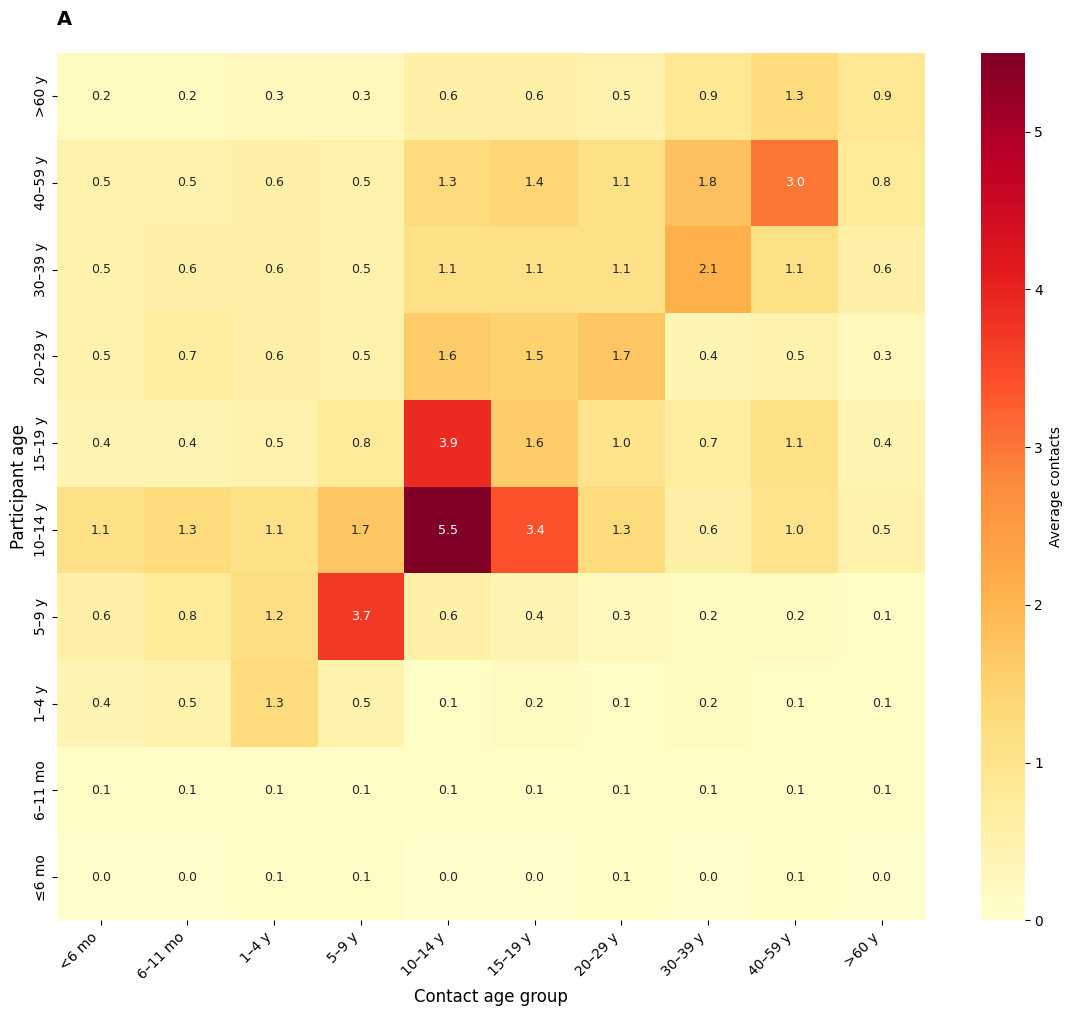

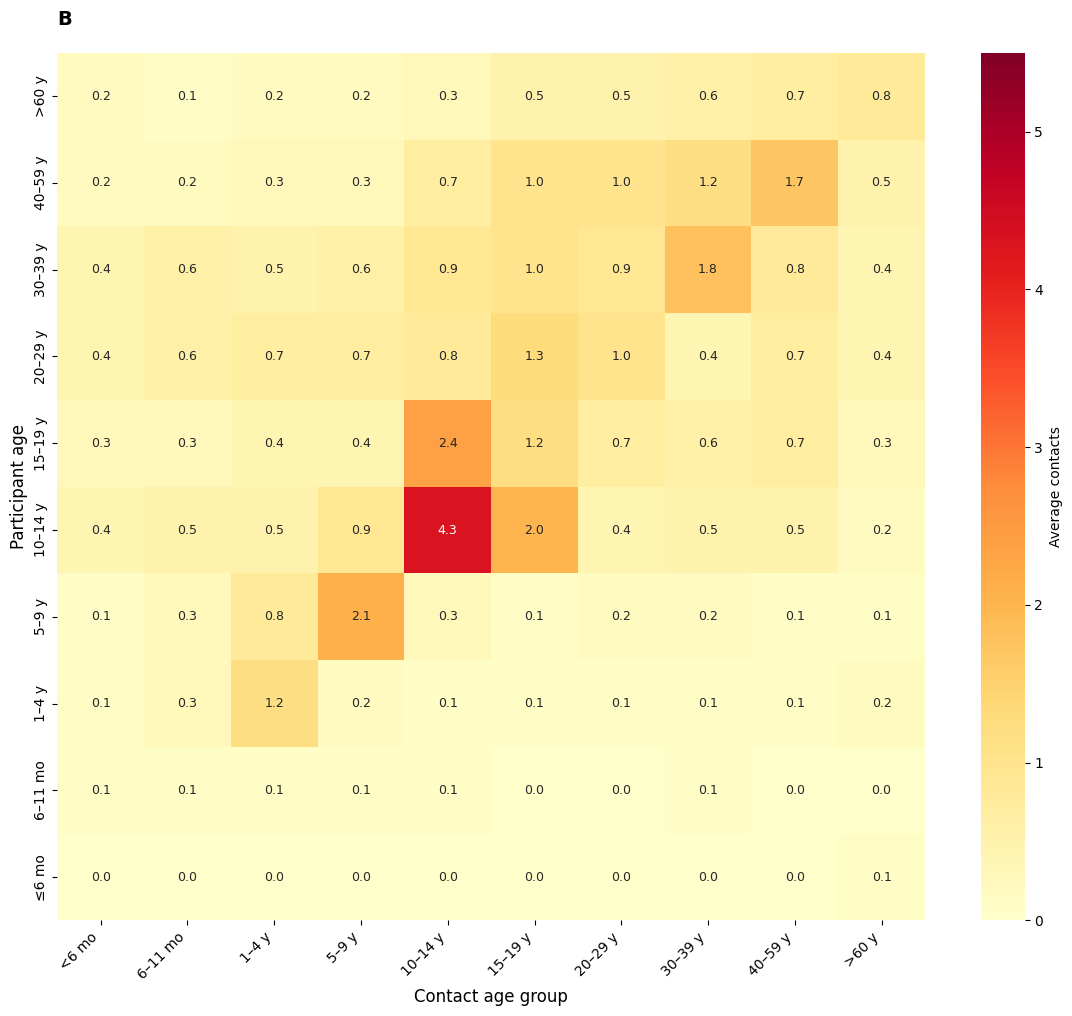

In [2]:
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Age group labels for y-axis (participant age) - from top to bottom as in figure
age_groups_y = [
    '>60 y',
    '40–59 y',
    '30–39 y',
    '20–29 y',
    '15–19 y',
    '10–14 y',
    '5–9 y',
    '1–4 y',
    '6–11 mo',
    '≤6 mo'
]

# Age group labels for x-axis (contact age) - from left to right as in figure
age_groups_x = [
    '<6 mo', '6–11 mo', '1–4 y', '5–9 y', '10–14 y',
    '15–19 y', '20–29 y', '30–39 y', '40–59 y', '>60 y'
]

# Rural contact matrix from Figure 2A (exactly as shown)
# Rows: participant age from top to bottom as in figure
rural_matrix = np.array([
    [0.2, 0.2, 0.3, 0.3, 0.6, 0.6, 0.5, 0.9, 1.3, 0.9],  # >60 y
    [0.5, 0.5, 0.6, 0.5, 1.3, 1.4, 1.1, 1.8, 3.0, 0.8],  # 40–59 y
    [0.5, 0.6, 0.6, 0.5, 1.1, 1.1, 1.1, 2.1, 1.1, 0.6],  # 30–39 y
    [0.5, 0.7, 0.6, 0.5, 1.6, 1.5, 1.7, 0.4, 0.5, 0.3],  # 20–29 y
    [0.4, 0.4, 0.5, 0.8, 3.9, 1.6, 1.0, 0.7, 1.1, 0.4],  # 15–19 y
    [1.1, 1.3, 1.1, 1.7, 5.5, 3.4, 1.3, 0.6, 1.0, 0.5],  # 10–14 y
    [0.6, 0.8, 1.2, 3.7, 0.6, 0.4, 0.3, 0.2, 0.2, 0.1],  # 5–9 y
    [0.4, 0.5, 1.3, 0.5, 0.1, 0.2, 0.1, 0.2, 0.1, 0.1],  # 1–4 y
    [0.1, 0.1, 0.1, 0.1, 0.1, 0.1, 0.1, 0.1, 0.1, 0.1],  # 6–11 mo
    [0.0, 0.0, 0.1, 0.1, 0.0, 0.0, 0.1, 0.0, 0.1, 0.0]   # ≤6 mo
])

# Urban contact matrix from Figure 2B (exactly as shown)
urban_matrix = np.array([
    [0.2, 0.1, 0.2, 0.2, 0.3, 0.5, 0.5, 0.6, 0.7, 0.8],
    [0.2, 0.2, 0.3, 0.3, 0.7, 1.0, 1.0, 1.2, 1.7, 0.5],  # >60 y
    [0.4, 0.6, 0.5, 0.6, 0.9, 1.0, 0.9, 1.8, 0.8, 0.4],  # 40–59 y
    [0.4, 0.6, 0.7, 0.7, 0.8, 1.3, 1.0, 0.4, 0.7, 0.4],  # 30–39 y
    [0.3, 0.3, 0.4, 0.4, 2.4, 1.2, 0.7, 0.6, 0.7, 0.3],  # 20–29 y
    [0.4, 0.5, 0.5, 0.9, 4.3, 2.0, 0.4, 0.5, 0.5, 0.2],  # 15–19 y
    [0.1, 0.3, 0.8, 2.1, 0.3, 0.1, 0.2, 0.2, 0.1, 0.1],  # 10–14 y
    [0.1, 0.3, 1.2, 0.2, 0.1, 0.1, 0.1, 0.1, 0.1, 0.2],  # 5–9 y
    [0.1, 0.1, 0.1, 0.1, 0.1, 0.0, 0.0, 0.1, 0.0, 0.0],  # 1–4 y
    [0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.1],  # 6–11 mo
#    [0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0]   # ≤6 mo
])

# Save the contact-matrix values and the age-group ordering used in this cell.
np.savetxt(DATA_RAW_DIR / "rural_contact_matrix_source_values.csv",
           rural_matrix, delimiter=",", fmt="%.6g")
np.savetxt(DATA_RAW_DIR / "urban_contact_matrix_source_values.csv",
           urban_matrix, delimiter=",", fmt="%.6g")
(DATA_RAW_DIR / "age_group_order.txt").write_text(
    "Rows: " + "; ".join(age_groups_y) + "\nColumns: " + "; ".join(age_groups_x) + "\n",
    encoding="utf-8"
)

# Print rural matrix exactly as in Figure 2A
print("=" * 90)
print("A")
print("-" * 90)
print(f"{'':12s}", end='')
for age in age_groups_x:
    print(f"{age:>10s}", end='')
print()
print()

for i, age in enumerate(age_groups_y):
    print(f"{age:12s}", end='')
    for j in range(len(age_groups_x)):
        if rural_matrix[i, j] == 0 and i >= 8:
            print(f"{' ':10s}", end='')
        else:
            val = rural_matrix[i, j]
            if val == int(val):
                print(f"{int(val):10d}", end='')
            else:
                print(f"{val:10.1f}", end='')
    print()
print("-" * 90)
print(f"{'':12s} <6 mo  6-11 mo")
print()
print(f"{'':50s}y")
print(f"{'':45s}Participant age")
print("=" * 90)

# Print urban matrix exactly as in Figure 2B
print("\n" + "=" * 90)
print("B")
print("-" * 90)
print(f"{'':12s}", end='')
for age in age_groups_x:
    print(f"{age:>10s}", end='')
print()
print()

for i, age in enumerate(age_groups_y):
    print(f"{age:12s}", end='')
    for j in range(len(age_groups_x)):
        if urban_matrix[i, j] == 0 and i >= 7:
            print(f"{' ':10s}", end='')
        else:
            val = urban_matrix[i, j]
            if val == int(val):
                print(f"{int(val):10d}", end='')
            else:
                print(f"{val:10.1f}", end='')
    print()
print("-" * 90)
print(f"{'':12s} <6 mo  6-11 mo")
print()
print(f"{'':50s}y")
print(f"{'':45s}Participant age")
print("=" * 90)

# Plot rural matrix
plt.figure(figsize=(12, 10))
sns.heatmap(
    rural_matrix,
    annot=True,
    fmt='.1f',
    cmap='YlOrRd',
    xticklabels=age_groups_x,
    yticklabels=age_groups_y,
    cbar_kws={'label': 'Average contacts'},
    square=True,
    annot_kws={'size': 9},
    vmin=0,
    vmax=5.5
)
plt.title('A', fontsize=14, fontweight='bold', loc='left', pad=20)
plt.xlabel('Contact age group', fontsize=12)
plt.ylabel('Participant age', fontsize=12)
plt.xticks(rotation=45, ha='right')
plt.tight_layout()
plt.savefig(FIG_CONTACT / "Rural_contact_matrix.png", dpi=300, bbox_inches="tight")
plt.show()

# Plot urban matrix
plt.figure(figsize=(12, 10))
sns.heatmap(
    urban_matrix,
    annot=True,
    fmt='.1f',
    cmap='YlOrRd',
    xticklabels=age_groups_x,
    yticklabels=age_groups_y,
    cbar_kws={'label': 'Average contacts'},
    square=True,
    annot_kws={'size': 9},
    vmin=0,
    vmax=5.5
)
plt.title('B', fontsize=14, fontweight='bold', loc='left', pad=20)
plt.xlabel('Contact age group', fontsize=12)
plt.ylabel('Participant age', fontsize=12)
plt.xticks(rotation=45, ha='right')
plt.tight_layout()
plt.savefig(FIG_CONTACT / "Urban_contact_matrix.png", dpi=300, bbox_inches="tight")
plt.show()

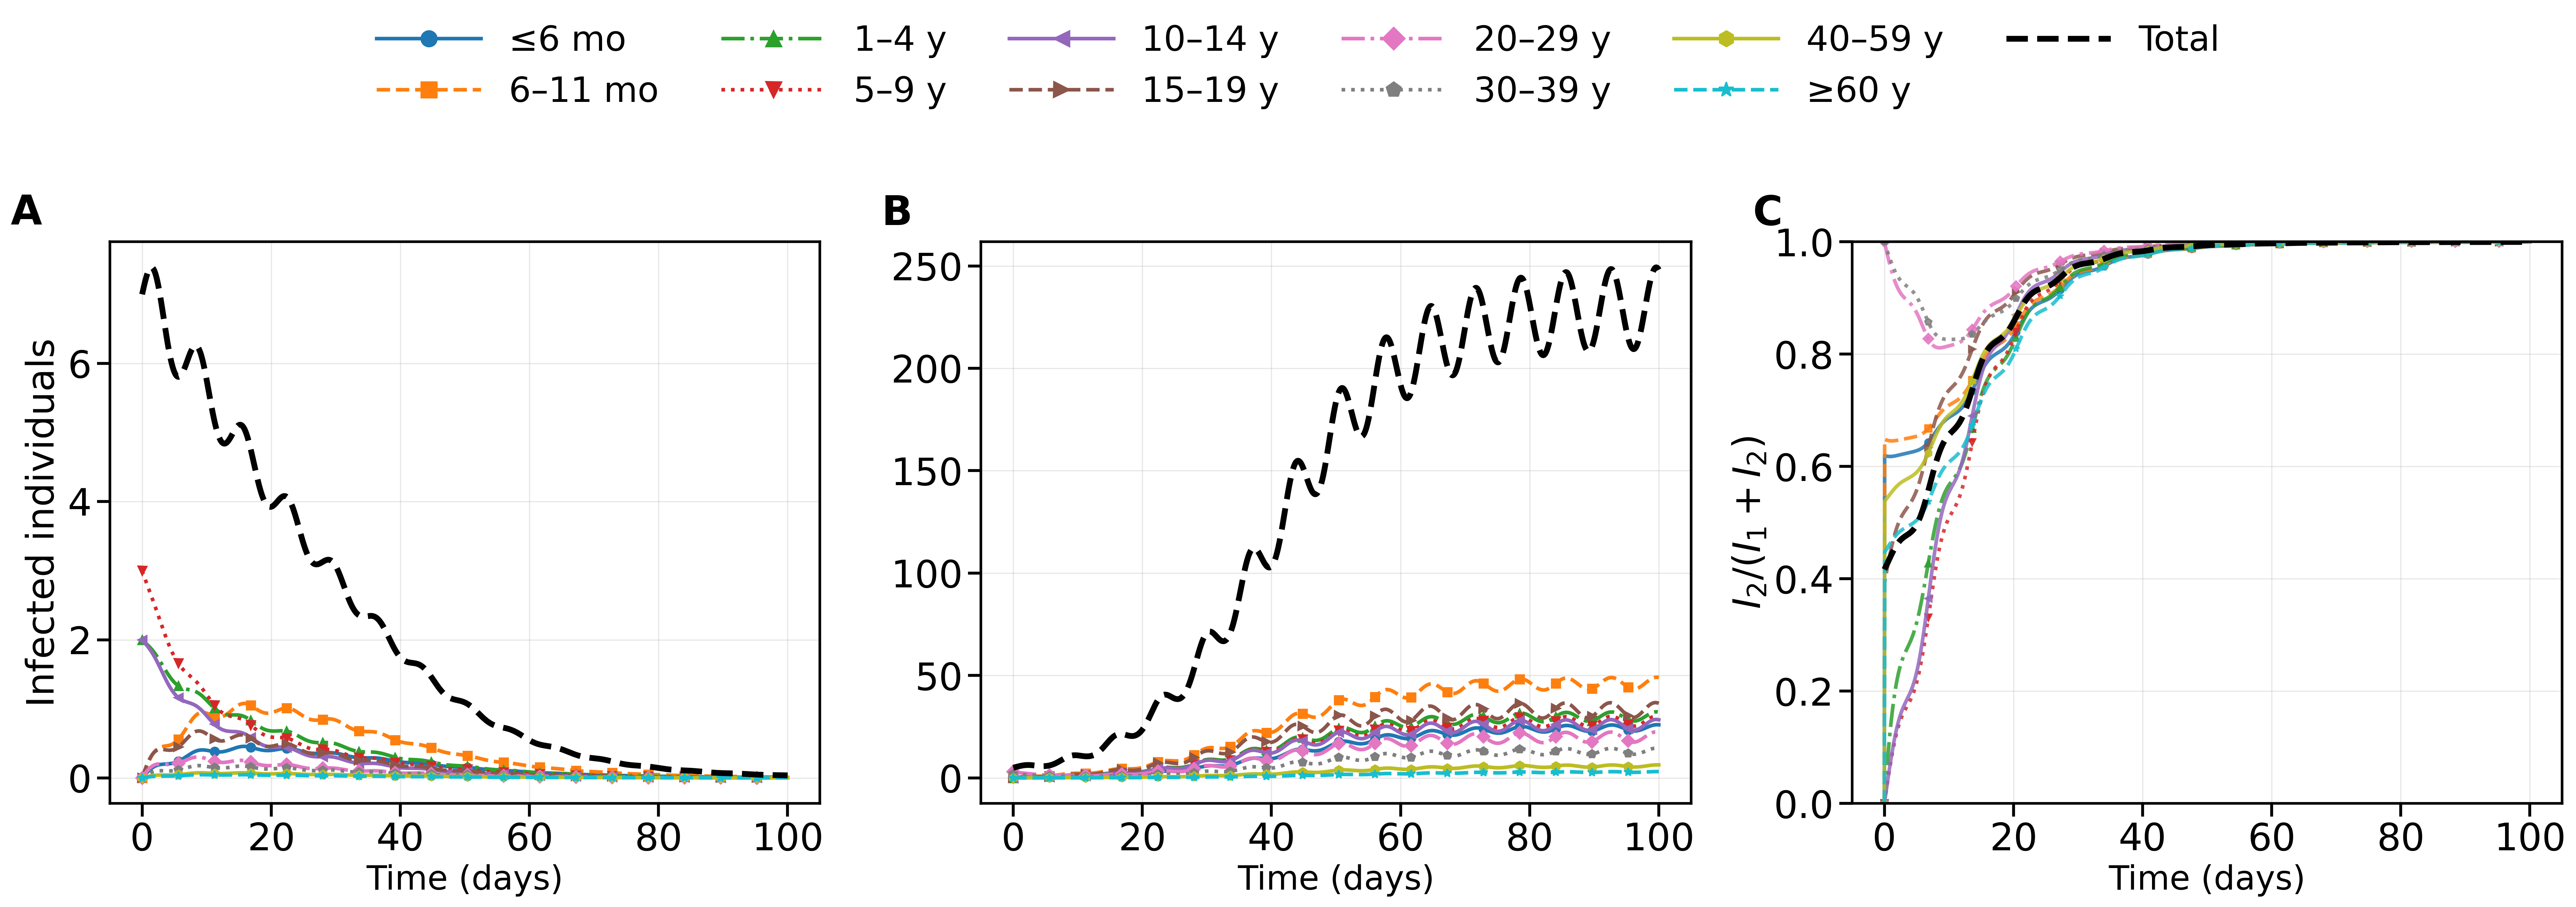

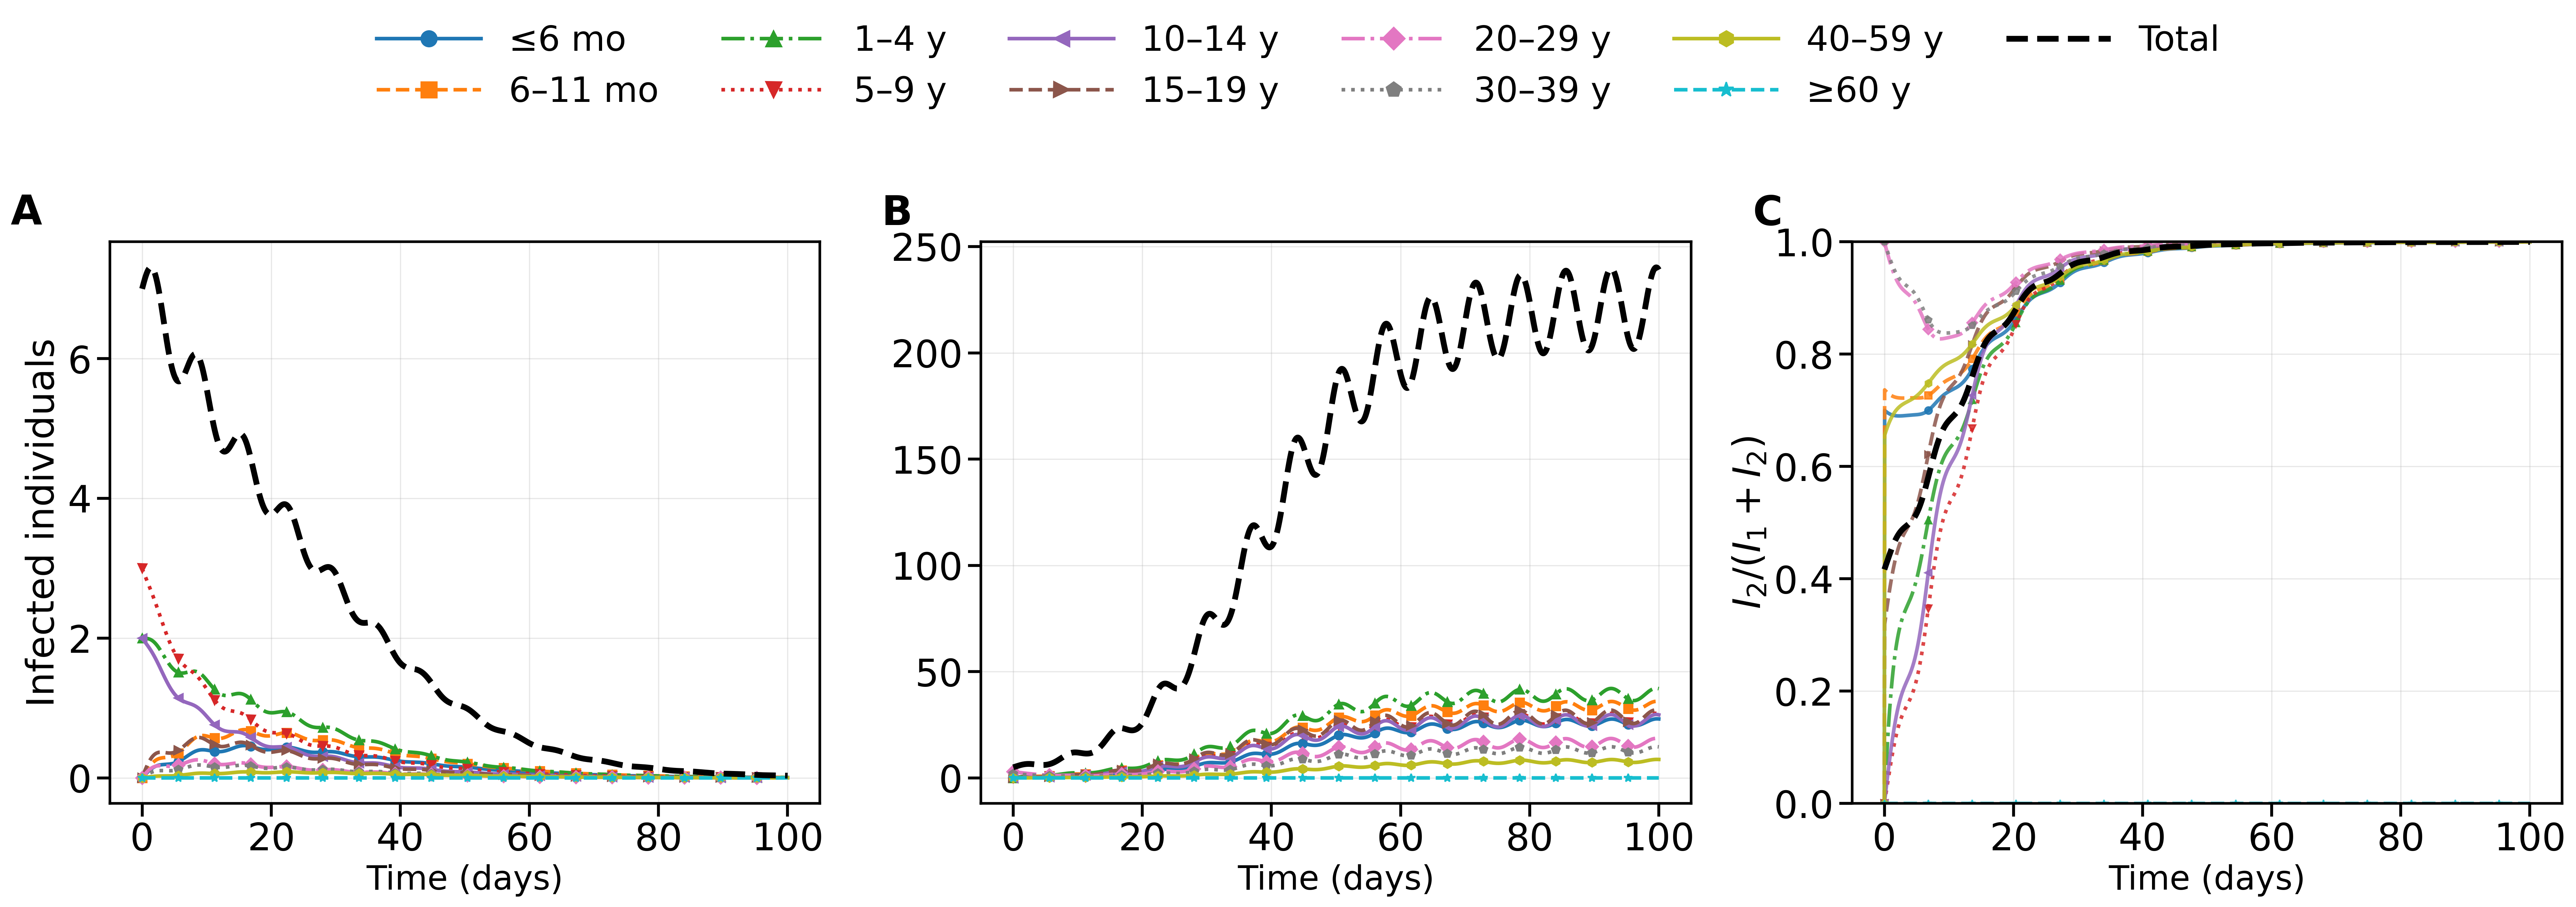

In [3]:
####################################################################################################
######################## AGE-STRUCTURED TWO-STRAIN MODEL : PUBLISHABLE #############################
######################## RURAL vs URBAN | NATURE COMMUNICATIONS STYLE ##############################
######################## AGE-WISE INFECTED COUNTS + PREVALENCE #####################################
####################################################################################################

import numpy as np
import matplotlib.pyplot as plt
from scipy.integrate import solve_ivp

# ===========================================
# GLOBAL STYLE
# ===========================================
plt.rcParams.update({
    "font.size": 20,
    "axes.linewidth": 1.8,
    "axes.labelsize": 20,
    "axes.titlesize": 25,
    "xtick.labelsize": 20,
    "ytick.labelsize": 20,
    "legend.fontsize": 18,
    "figure.dpi": 300,
    "savefig.dpi": 300
})

# ===========================================
# AGE GROUPS
# ===========================================
age_groups = [
    '≤6 mo','6–11 mo','1–4 y','5–9 y','10–14 y',
    '15–19 y','20–29 y','30–39 y','40–59 y','≥60 y'
]

R = len(age_groups)

# ===========================================
# POPULATION DATA
# ===========================================
# Rural total = 676
rural_population = np.array([
    62, 82, 63, 64, 61,
    64, 64, 64, 89, 63
])

# Urban total = 687
urban_population = np.array([
    66, 64, 72, 58, 64,
    60, 61, 61, 120, 61
])

# ===========================================
# CONTACT MATRICES
# ===========================================
rural = np.array([
    [0.2,0.2,0.3,0.3,0.6,0.6,0.5,0.9,1.3,0.9],
    [0.5,0.5,0.6,0.5,1.3,1.4,1.1,1.8,3.0,0.8],
    [0.5,0.6,0.6,0.5,1.1,1.1,1.1,2.1,1.1,0.6],
    [0.5,0.7,0.6,0.5,1.6,1.5,1.7,0.4,0.5,0.3],
    [0.4,0.4,0.5,0.8,3.9,1.6,1.0,0.7,1.1,0.4],
    [1.1,1.3,1.1,1.7,5.5,3.4,1.3,0.6,1.0,0.5],
    [0.6,0.8,1.2,3.7,0.6,0.4,0.3,0.2,0.2,0.1],
    [0.4,0.5,1.3,0.5,0.1,0.2,0.1,0.2,0.1,0.1],
    [0.1,0.0,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1],
    [0.0,0.0,0.1,0.1,0.0,0.0,0.1,0.0,0.1,0.0]
])

urban = np.array([
    [0.2,0.1,0.2,0.2,0.3,0.5,0.5,0.6,0.7,0.8],
    [0.2,0.2,0.3,0.3,0.7,1.0,1.0,1.2,1.7,0.5],
    [0.4,0.6,0.5,0.6,0.9,1.0,0.9,1.8,0.8,0.4],
    [0.4,0.6,0.7,0.7,0.8,1.3,1.0,0.4,0.7,0.4],
    [0.3,0.3,0.4,0.4,2.4,1.2,0.7,0.6,0.7,0.3],
    [0.4,0.5,0.5,0.9,4.3,2.0,0.4,0.5,0.5,0.2],
    [0.1,0.3,0.8,2.1,0.3,0.1,0.2,0.2,0.1,0.1],
    [0.1,0.3,1.2,0.2,0.1,0.1,0.1,0.1,0.1,0.2],
    [0.1,0.1,0.1,0.0,0.0,0.0,0.0,0.1,0.0,0.0],
    [0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.1]
])

# ===========================================
# NORMALIZATION
# ===========================================
def normalize(C):
    return C / np.mean(np.sum(C, axis=1))

rural_matrix = normalize(rural)
urban_matrix = normalize(urban)

# Save population vectors and normalized contact matrices.
np.savetxt(DATA_PROCESSED_DIR / "rural_population_by_age.csv", rural_population, delimiter=",", fmt="%.10g")
np.savetxt(DATA_PROCESSED_DIR / "urban_population_by_age.csv", urban_population, delimiter=",", fmt="%.10g")
np.savetxt(DATA_PROCESSED_DIR / "rural_contact_matrix_normalized.csv", rural_matrix, delimiter=",", fmt="%.10g")
np.savetxt(DATA_PROCESSED_DIR / "urban_contact_matrix_normalized.csv", urban_matrix, delimiter=",", fmt="%.10g")

# ===========================================
# PARAMETERS
# ===========================================
beta1 = np.array([0.35,0.32,0.28,0.25,0.22,0.20,0.18,0.22,0.28,0.32])
beta2 = np.array([0.45,0.42,0.38,0.35,0.32,0.30,0.28,0.32,0.38,0.42])

gamma1 = np.array([0.10,0.10,0.12,0.14,0.16,0.18,0.20,0.18,0.14,0.10])
gamma2 = np.array([0.09,0.09,0.11,0.13,0.15,0.17,0.19,0.17,0.13,0.09])

L = np.diag([0.2,0.3,0.4,0.5,0.6,0.7,0.8,0.7,0.5,0.4])

B1 = np.diag(beta1)
B2 = np.diag(beta2)

# ===========================================
# PERIODIC FORCING
# ===========================================
A = 0.6
omega = 2*np.pi/7

def contact_factor(t):
    return 1 + A*np.cos(omega*t)

# ===========================================
# SIMULATION
# ===========================================
def simulate(C, population, alpha=0.6, t_max=100):

    def model(t, y):

        I1 = y[:R]
        I2 = y[R:]

        S = np.maximum(population - I1 - I2, 1e-10)

        frac_I1 = I1 / population
        frac_I2 = I2 / population

        lam1 = contact_factor(t) * (C @ (B1 @ frac_I1))
        lam2 = contact_factor(t) * (C @ (B2 @ frac_I2))

        eff1 = (np.eye(R) - L) @ lam1
        eff2 = (np.eye(R) - alpha * L) @ lam2

        dI1 = S * eff1 - gamma1 * I1
        dI2 = S * eff2 - gamma2 * I2

        return np.concatenate([dI1, dI2])

    # ===========================================
    # INITIAL CONDITIONS
    # ===========================================
    y0 = np.zeros(2 * R)

    # Strain-1 seeds
    y0[2] = 2
    y0[3] = 3
    y0[4] = 2

    # Strain-2 seeds
    y0[R + 6] = 3
    y0[R + 7] = 2

    t_eval = np.linspace(0, t_max, 2500)

    sol = solve_ivp(
        model,
        (0, t_max),
        y0,
        method='RK45',
        t_eval=t_eval,
        rtol=1e-7,
        atol=1e-9
    )

    return sol

# ===========================================
# PLOTTING FUNCTION
# ===========================================
def plot_site(C, population, name, alpha=0.6):

    sol = simulate(C, population, alpha)

    t = sol.t

    I1 = sol.y[:R]
    I2 = sol.y[R:]

    prev1 = np.sum(I1, axis=0)
    prev2 = np.sum(I2, axis=0)

    dominance_total = prev2 / (prev1  + prev2+1e-12)

    # Save age-wise infection trajectories and total strain prevalence.
    trajectory_columns = [t]
    trajectory_headers = ["time_days"]
    for _i, _age in enumerate(age_groups):
        trajectory_columns.append(I1[_i])
        trajectory_headers.append(f"I1_{_age}")
    for _i, _age in enumerate(age_groups):
        trajectory_columns.append(I2[_i])
        trajectory_headers.append(f"I2_{_age}")
    trajectory_columns.extend([prev1, prev2, dominance_total])
    trajectory_headers.extend(["I1_total", "I2_total", "strain2_dominance_total"])
    np.savetxt(
        CSV_EPIDEMIC / f"{name.lower()}_epidemic_trajectories.csv",
        np.column_stack(trajectory_columns), delimiter=",",
        header=",".join(trajectory_headers), comments="", fmt="%.10g"
    )

    # ===========================================
    # ORIGINAL COLORS / LINESTYLES / MARKERS
    # ===========================================
    colors = plt.cm.tab10(np.linspace(0,1,R))

    linestyles = ['-', '--', '-.', ':']

    markers = ['o','s','^','v','<','>','D','p','h','*']

    # ===========================================
    # FIGURE
    # ===========================================
    fig, axes = plt.subplots(
        1, 3,
        figsize=(25,8)
    )

    # ===========================================
    # STRAIN 1
    # ===========================================
    for i in range(R):

        axes[0].plot(
            t,
            I1[i],
            color=colors[i],
            linestyle=linestyles[i % 4],
            marker=markers[i],
            markevery=140,
            lw=2.5,
            ms=6,
            label=age_groups[i]
        )

    axes[0].plot(
        t,
        prev1,
        'k--',
        lw=4,
        label='Total'
    )

#    axes[0].set_title(
#        f"A",
#        fontweight='bold'
#    )
    axes[0].text(
    -0.14,
    1.03,
    'A',
    transform=axes[0].transAxes,
    fontsize=28,
    fontweight='bold'
)
    axes[0].set_ylabel(
        "Infected individuals",
        fontsize=26
    )

    # ===========================================
    # STRAIN 2
    # ===========================================
    for i in range(R):

        axes[1].plot(
            t,
            I2[i],
            color=colors[i],
            linestyle=linestyles[i % 4],
            marker=markers[i],
            markevery=140,
            lw=2.5,
            ms=6
        )

    axes[1].plot(
        t,
        prev2,
        'k--',
        lw=4
    )

#    axes[1].set_title(
#        f" B",
#        fontweight='bold'
#    )
    axes[1].text(
    -0.14,
    1.03,
    'B',
    transform=axes[1].transAxes,
    fontsize=28,
    fontweight='bold'
)    
    # ===========================================
    # DOMINANCE
    # ===========================================
    for i in range(R):

        dom_i = I2[i] / (I1[i] + I2[i]+1e-12)

        axes[2].plot(
            t,
            dom_i,
            color=colors[i],
            linestyle=linestyles[i % 4],
            marker=markers[i],
            markevery=170,
            lw=2.5,
            ms=5,
            alpha=0.85
        )

    axes[2].plot(
        t,
        dominance_total,
        'k--',
        lw=4,
        label='Total dominance'
    )

    axes[2].set_ylim(0,1)

#    axes[2].set_title(
#        f"C",
#        fontweight='bold'
#    )
    axes[2].text(
    -0.14,
    1.03,
    'C',
    transform=axes[2].transAxes,
    fontsize=28,
    fontweight='bold'
)
    axes[2].set_ylabel(
        r"$I_2/(I_1 + I_2)$",
        fontsize=26
    )

    # ===========================================
    # COMMON FORMATTING
    # ===========================================
    for ax in axes:

        ax.set_xlabel(
            "Time (days)",
            fontsize=23
        )

        ax.grid(alpha=0.3)

        ax.tick_params(
            axis='both',
            labelsize=26,
            width=2.0,
            length=9
        )

        ax.spines['top'].set_visible(True)
        ax.spines['right'].set_visible(True)

    # ===========================================
    # BIG LEGEND
    # ===========================================
    handles, labels = axes[0].get_legend_handles_labels()

    fig.legend(
        handles,
        labels,
        loc='upper center',
        bbox_to_anchor=(0.5, 1.12),
        ncol=6,
        fontsize=24,
        frameon=False,
        handlelength=3.0,
        handletextpad=0.8,
        columnspacing=1.8,
        markerscale=1.8
    )
    
    # ===========================================
    # LAYOUT + SAVE
    # ===========================================
    plt.tight_layout(rect=[0,0,1,0.92])

    plt.savefig(
        FIG_EPIDEMIC / f"{name}_prevalence_Mozambique.png",
        dpi=300,
        bbox_inches='tight'
    )

    plt.show()

# ===========================================
# RUN
# ===========================================
plot_site(
    rural_matrix,
    rural_population,
    "Rural"
)

plot_site( 
    urban_matrix,
    urban_population,
    "Urban"
)


Computing Rural beta-eta maps
eta = 1/60
eta = 2/60
eta = 3/60
eta = 4/60
eta = 5/60
eta = 6/60
eta = 7/60
eta = 8/60
eta = 9/60
eta = 10/60
eta = 11/60
eta = 12/60
eta = 13/60
eta = 14/60
eta = 15/60
eta = 16/60
eta = 17/60
eta = 18/60
eta = 19/60
eta = 20/60
eta = 21/60
eta = 22/60
eta = 23/60
eta = 24/60
eta = 25/60
eta = 26/60
eta = 27/60
eta = 28/60
eta = 29/60
eta = 30/60
eta = 31/60
eta = 32/60
eta = 33/60
eta = 34/60
eta = 35/60
eta = 36/60
eta = 37/60
eta = 38/60
eta = 39/60
eta = 40/60
eta = 41/60
eta = 42/60
eta = 43/60
eta = 44/60
eta = 45/60
eta = 46/60
eta = 47/60
eta = 48/60
eta = 49/60
eta = 50/60
eta = 51/60
eta = 52/60
eta = 53/60
eta = 54/60
eta = 55/60
eta = 56/60
eta = 57/60
eta = 58/60
eta = 59/60
eta = 60/60

Computing Urban beta-eta maps
eta = 1/60
eta = 2/60
eta = 3/60
eta = 4/60
eta = 5/60
eta = 6/60
eta = 7/60
eta = 8/60
eta = 9/60
eta = 10/60
eta = 11/60
eta = 12/60
eta = 13/60
eta = 14/60
eta = 15/60
eta = 16/60
eta = 17/60
eta = 18/60
eta = 19/60
eta = 20

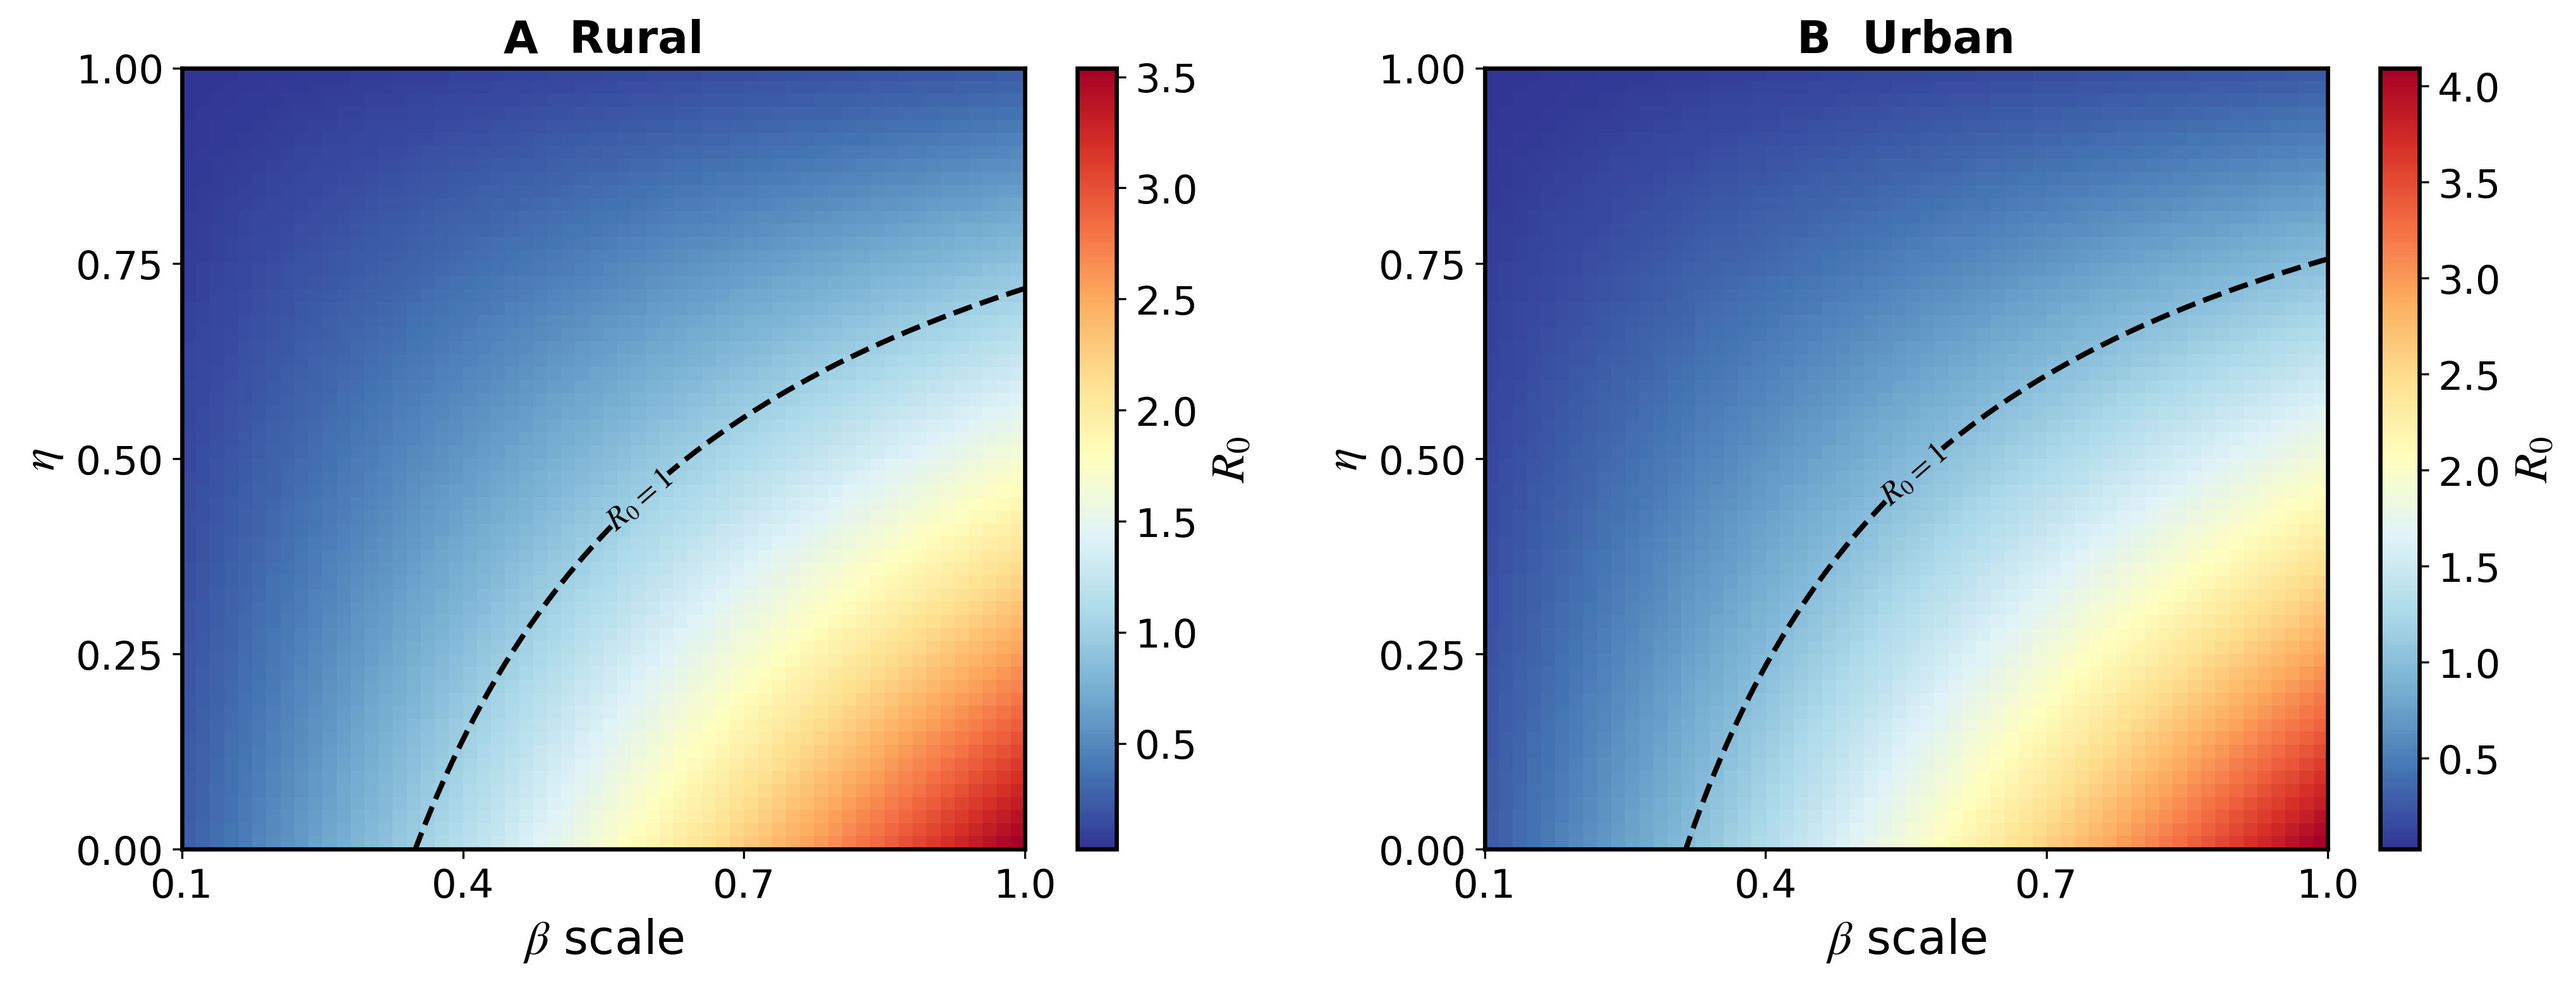

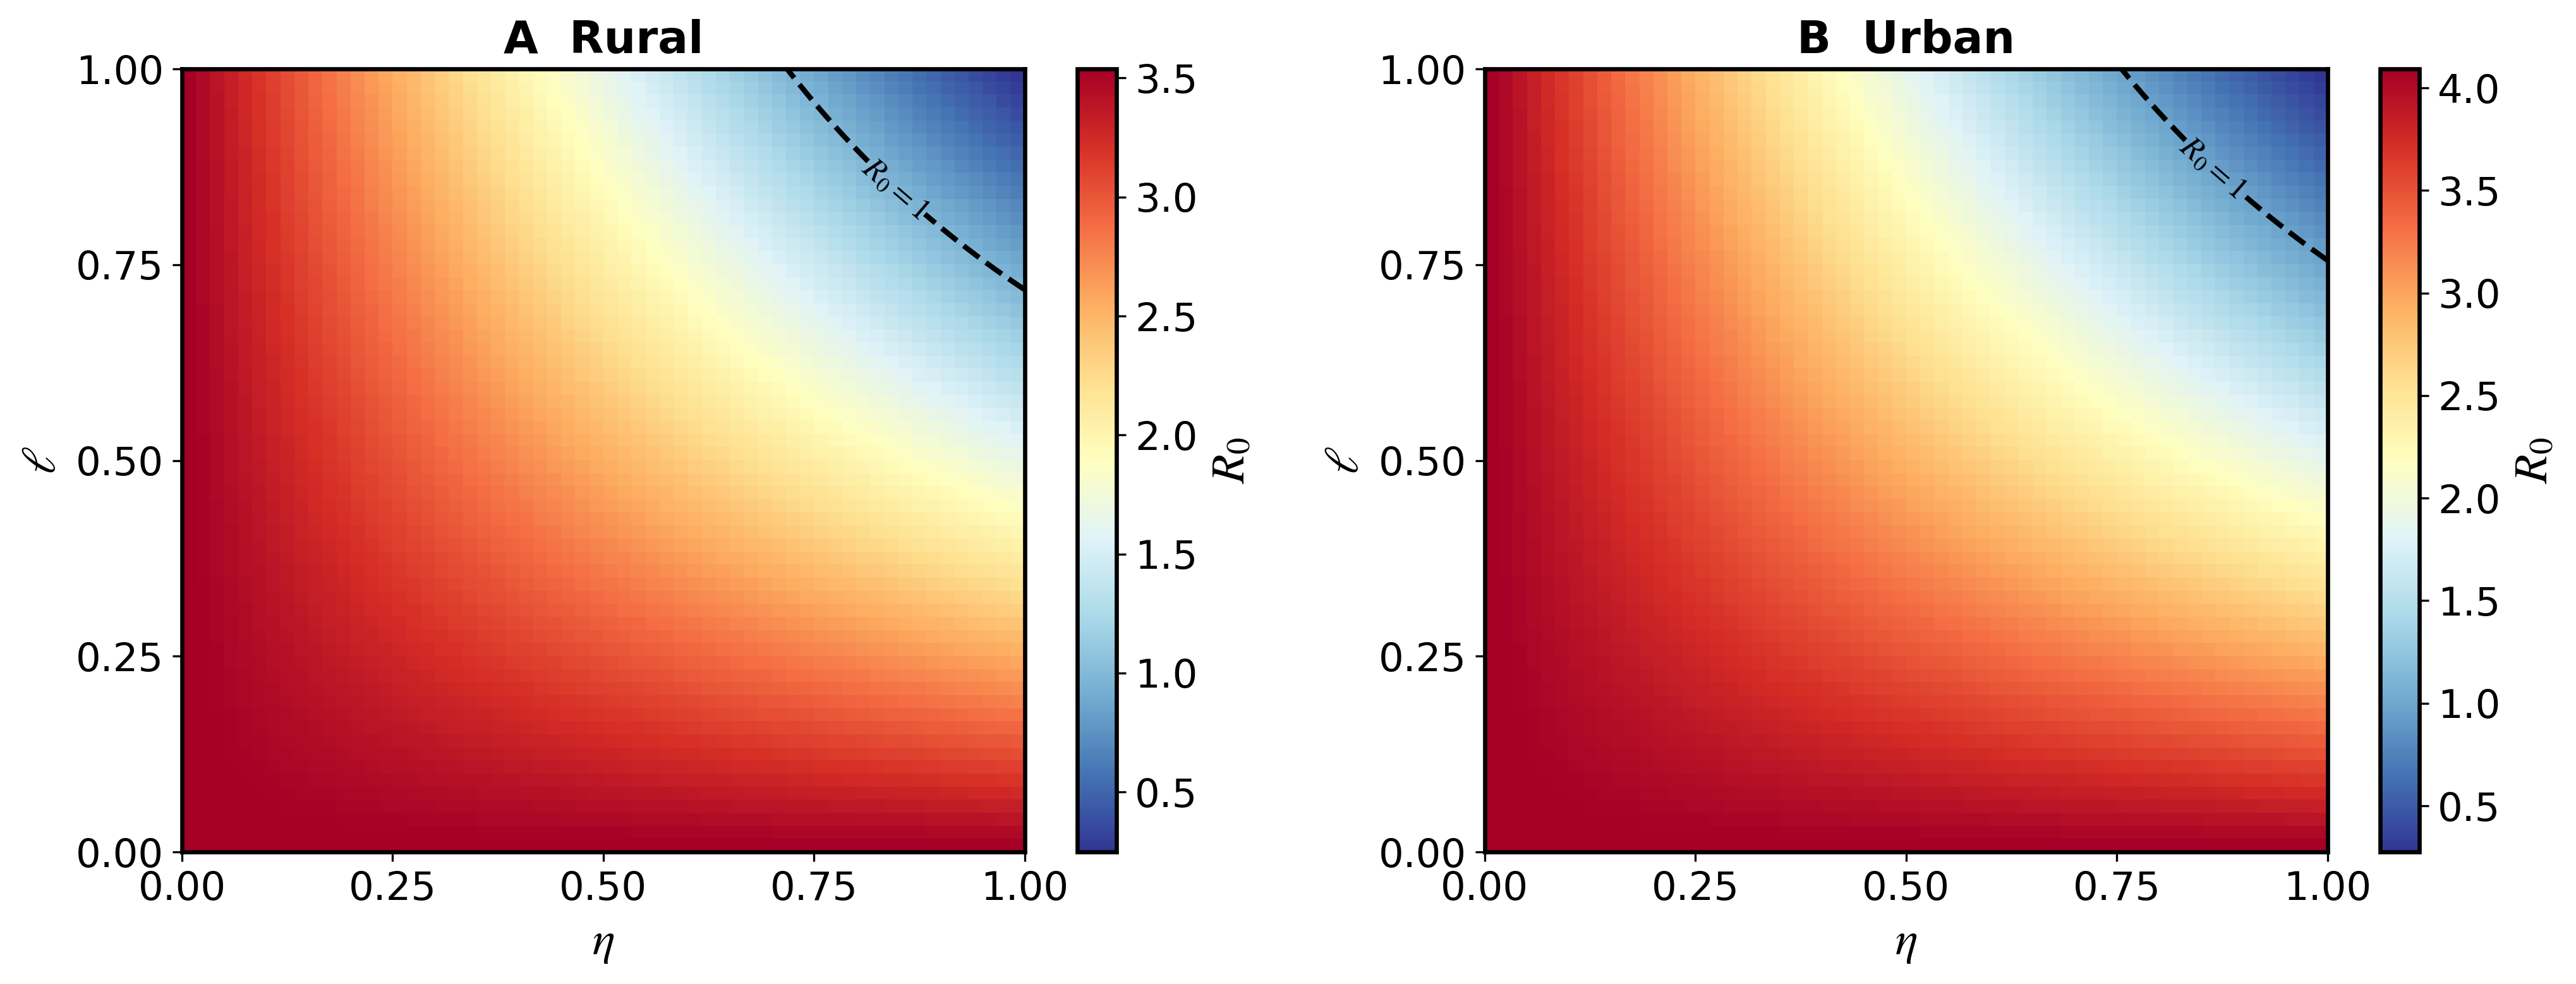

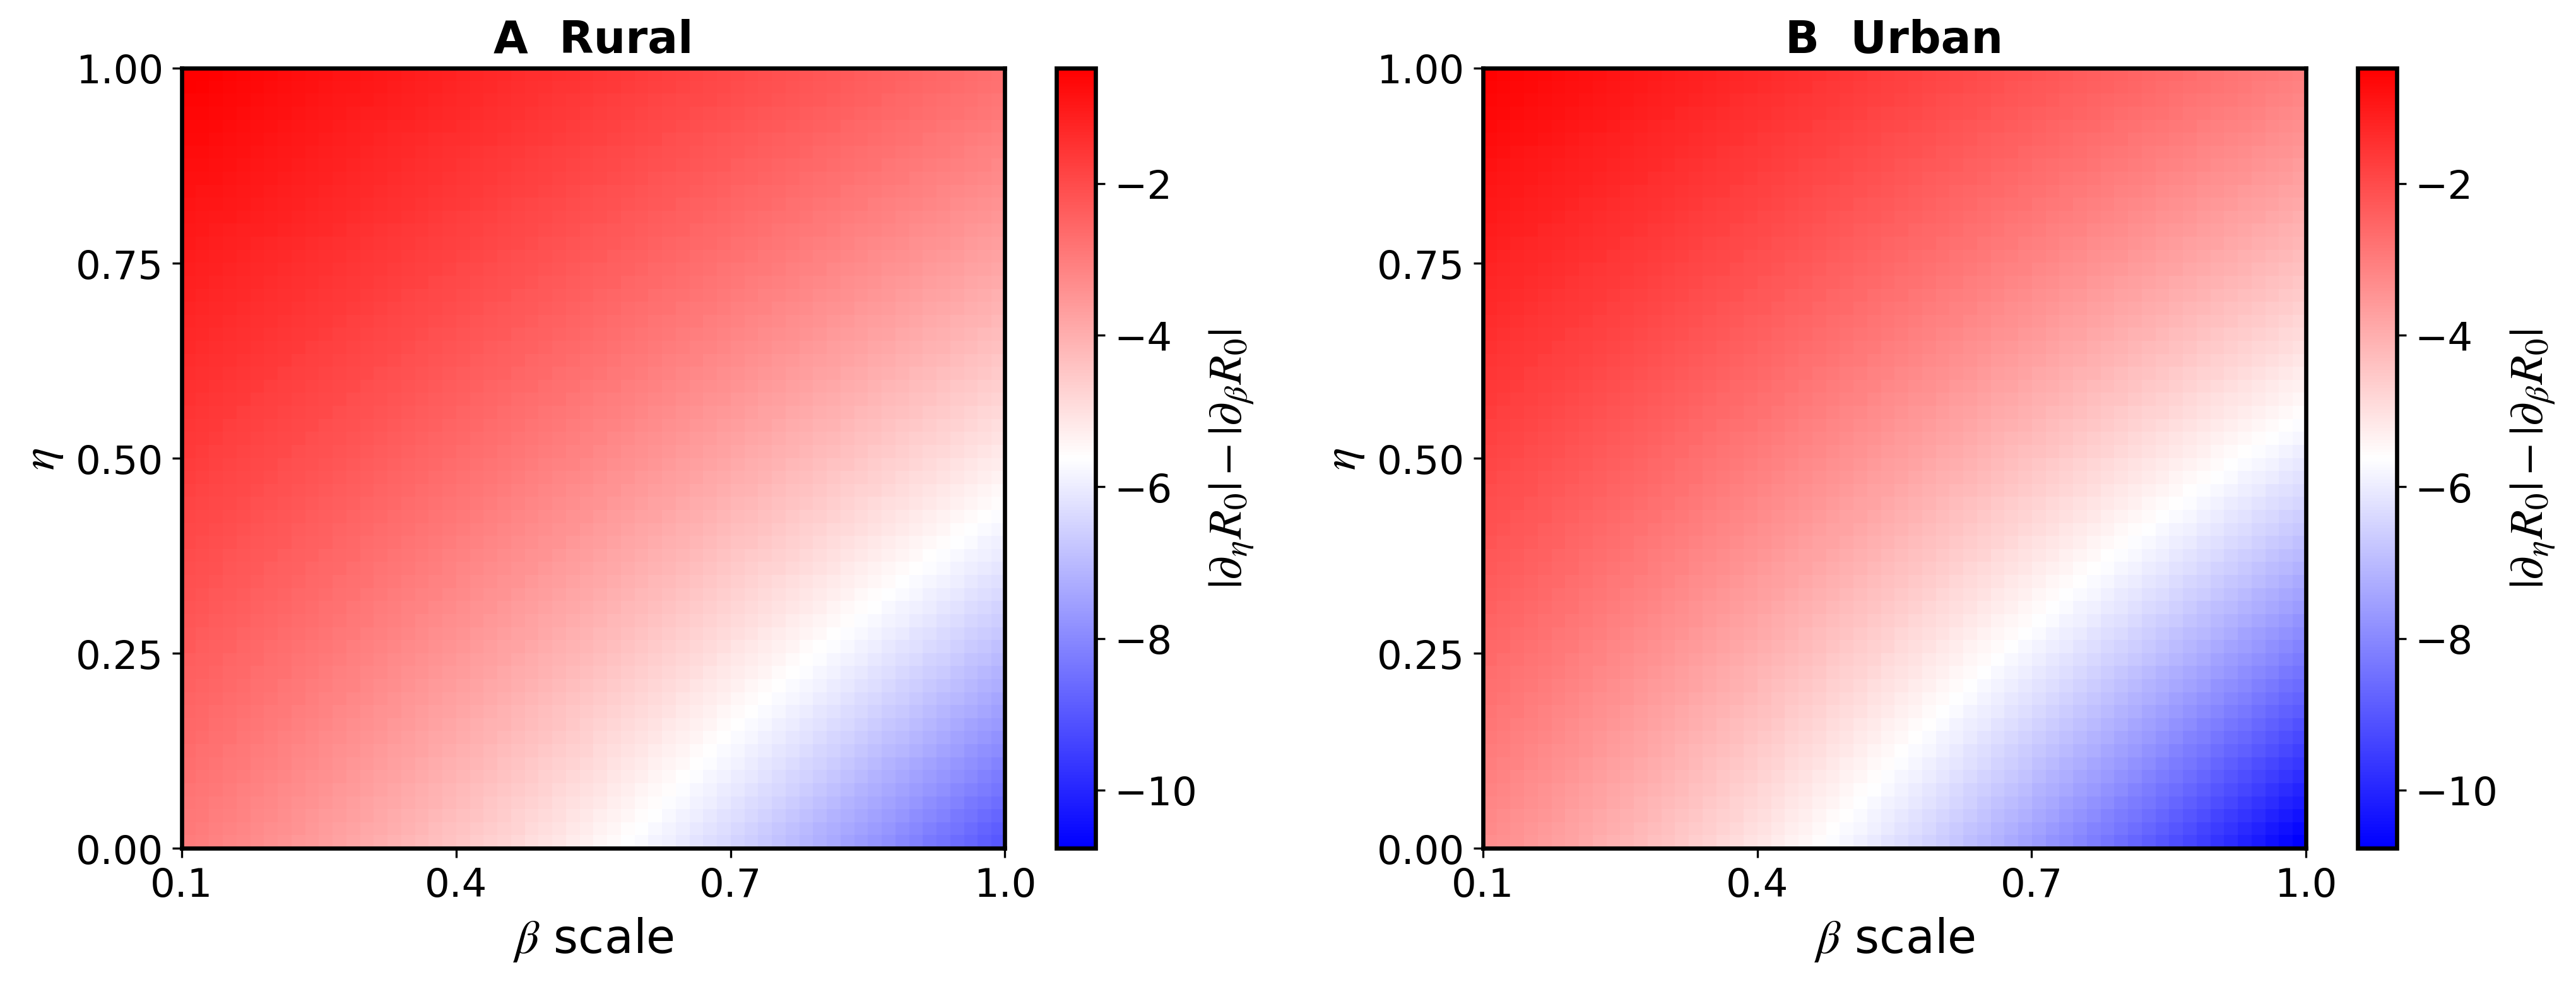

In [4]:


import numpy as np
import matplotlib.pyplot as plt
import pandas as pd
from scipy.linalg import eigvals, expm

# ============================================================
# GLOBAL STYLE (Nature Communications-like)
# ============================================================
plt.rcParams.update({
    "font.size": 17,
    "axes.linewidth": 1.6,
    "axes.labelsize": 18,
    "axes.titlesize": 17,
    "xtick.labelsize": 15,
    "ytick.labelsize": 15,
    "legend.fontsize": 12,
    "figure.titlesize": 18,
    "font.family": "sans-serif",
    "mathtext.fontset": "stix",
})

# ============================================================
# DIMENSION
# ============================================================
R = 10

# ============================================================
# CONTACT MATRICES
# ============================================================
rural_raw = np.array([
    [0.2,0.2,0.3,0.3,0.6,0.6,0.5,0.9,1.3,0.9],
    [0.5,0.5,0.6,0.5,1.3,1.4,1.1,1.8,3.0,0.8],
    [0.5,0.6,0.6,0.5,1.1,1.1,1.1,2.1,1.1,0.6],
    [0.5,0.7,0.6,0.5,1.6,1.5,1.7,0.4,0.5,0.3],
    [0.4,0.4,0.5,0.8,3.9,1.6,1.0,0.7,1.1,0.4],
    [1.1,1.3,1.1,1.7,5.5,3.4,1.3,0.6,1.0,0.5],
    [0.6,0.8,1.2,3.7,0.6,0.4,0.3,0.2,0.2,0.1],
    [0.4,0.5,1.3,0.5,0.1,0.2,0.1,0.2,0.1,0.1],
    [0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1],
    [0.0,0.0,0.1,0.1,0.0,0.0,0.1,0.0,0.1,0.0]
])

urban_raw = np.array([
    [0.2,0.1,0.2,0.2,0.3,0.5,0.5,0.6,0.7,0.8],
    [0.2,0.2,0.3,0.3,0.7,1.0,1.0,1.2,1.7,0.5],
    [0.4,0.6,0.5,0.6,0.9,1.0,0.9,1.8,0.8,0.4],
    [0.4,0.6,0.7,0.7,0.8,1.3,1.0,0.4,0.7,0.4],
    [0.3,0.3,0.4,0.4,2.4,1.2,0.7,0.6,0.7,0.3],
    [0.4,0.5,0.5,0.9,4.3,2.0,0.4,0.5,0.5,0.2],
    [0.1,0.3,0.8,2.1,0.3,0.1,0.2,0.2,0.1,0.1],
    [0.1,0.3,1.2,0.2,0.1,0.1,0.1,0.1,0.1,0.2],
    [0.1,0.1,0.1,0.0,0.0,0.0,0.0,0.1,0.0,0.0],
    [0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.1]
])

# ============================================================
# NORMALIZATION
# ============================================================
def normalize(C):
    return C / np.max(np.sum(C, axis=1))

rural = normalize(rural_raw[::-1, ::-1])
urban = normalize(urban_raw[::-1, ::-1])

# ============================================================
# EPIDEMIOLOGICAL PARAMETERS
# ============================================================
beta_base = np.array([
    0.25,0.22,0.28,0.15,0.22,
    0.20,0.18,0.12,0.18,0.22
])

gamma = np.array([
    0.12,0.10,0.18,0.16,0.16,
    0.18,0.20,0.18,0.14,0.10
])

B_base = np.diag(beta_base)

V = np.diag(gamma)
V_inv = np.linalg.inv(V)

L_base = np.diag([
    0.95,0.95,0.90,0.90,0.90,
    0.90,0.95,0.95,0.90,0.90
])

# ============================================================
# PERIODIC FORCING
# ============================================================
A = 0.6
omega = 2*np.pi/7

def contact_factor(t):
    return 1 + A*np.cos(omega*t)

# ============================================================
# BUILD F
# ============================================================
def build_F(t, C, beta_scale, eta, ell):

    B = beta_scale * B_base
    L = ell * L_base

    cf = contact_factor(t)

    F = cf * (np.eye(R) - eta*L) @ C @ B

    return F

# ============================================================
# NEXT GENERATION OPERATOR
# ============================================================
def compute_K(C, beta_scale, eta, ell, q=20, T=7):

    dt = T/q

    Phi = np.eye(R)
    K = np.zeros((R,R))

    for k in range(q):

        t = k*dt

        F = build_F(t, C, beta_scale, eta, ell)

        A_mat = F - V

        Phi_step = expm(A_mat * dt)

        Phi = Phi_step @ Phi

        K += V_inv @ F @ Phi * dt

    return K

# ============================================================
# R0
# ============================================================
def compute_R0(C, beta_scale, eta, ell):

    K = compute_K(C, beta_scale, eta, ell)

    return np.max(np.real(eigvals(K)))

# ============================================================
# GRIDS
# ============================================================
beta_vals = np.linspace(0.1, 1.0, 60)

eta_vals = np.linspace(0.0, 1.0, 60)

ell_vals = np.linspace(0.0, 1.0, 60)

# ============================================================
# MAPS : beta vs eta
# ============================================================
def compute_beta_eta_maps(C, ell_fixed=1.0):

    R0_map = np.zeros((len(eta_vals), len(beta_vals)))

    for i, eta in enumerate(eta_vals):

        print(f"eta = {i+1}/{len(eta_vals)}")

        for j, beta in enumerate(beta_vals):

            R0_map[i,j] = compute_R0(
                C,
                beta_scale=beta,
                eta=eta,
                ell=ell_fixed
            )

    dR_deta, dR_dbeta = np.gradient(
        R0_map,
        eta_vals,
        beta_vals
    )

    Dominance = dR_deta - dR_dbeta

    return R0_map, Dominance

# ============================================================
# MAPS : ell vs eta
# ============================================================
def compute_ell_eta_maps(C, beta_fixed=1.0):

    R0_map = np.zeros((len(ell_vals), len(eta_vals)))

    for i, ell in enumerate(ell_vals):

        print(f"ell = {i+1}/{len(ell_vals)}")

        for j, eta in enumerate(eta_vals):

            R0_map[i,j] = compute_R0(
                C,
                beta_scale=beta_fixed,
                eta=eta,
                ell=ell
            )

    dR_dell, dR_deta = np.gradient(
        R0_map,
        ell_vals,
        eta_vals
    )

    Dominance = dR_deta - dR_dell

    return R0_map, Dominance

# ============================================================
# COMPUTE ALL
# ============================================================
print("\nComputing Rural beta-eta maps")
rural_beta_R0, rural_beta_D = compute_beta_eta_maps(rural)

print("\nComputing Urban beta-eta maps")
urban_beta_R0, urban_beta_D = compute_beta_eta_maps(urban)

print("\nComputing Rural ell-eta maps")
rural_ell_R0, rural_ell_D = compute_ell_eta_maps(rural)

print("\nComputing Urban ell-eta maps")
urban_ell_R0, urban_ell_D = compute_ell_eta_maps(urban)

# Save all computed R0 and dominance maps for later inspection/reuse.
np.savez_compressed(
    RESULT_NUMPY / "rural_urban_R0_and_dominance_maps.npz",
    beta_vals=beta_vals, eta_vals=eta_vals, ell_vals=ell_vals,
    rural_beta_R0=rural_beta_R0, rural_beta_D=rural_beta_D,
    urban_beta_R0=urban_beta_R0, urban_beta_D=urban_beta_D,
    rural_ell_R0=rural_ell_R0, rural_ell_D=rural_ell_D,
    urban_ell_R0=urban_ell_R0, urban_ell_D=urban_ell_D
)

# Export R0 parameter maps as readable CSV files.
for _site, _beta_map, _ell_map in [
    ("rural", rural_beta_R0, rural_ell_R0),
    ("urban", urban_beta_R0, urban_ell_R0)
]:
    _beta_df = pd.DataFrame(_beta_map, index=eta_vals, columns=beta_vals)
    _beta_df.index.name = "eta"
    _beta_df.to_csv(CSV_R0 / f"{_site}_R0_beta_eta.csv")
    _ell_df = pd.DataFrame(_ell_map, index=ell_vals, columns=eta_vals)
    _ell_df.index.name = "ell"
    _ell_df.to_csv(CSV_R0 / f"{_site}_R0_ell_eta.csv")


# ============================================================
# COMMON COLOR LIMITS
# ============================================================
dom_beta_vmin = min(rural_beta_D.min(), urban_beta_D.min())
dom_beta_vmax = max(rural_beta_D.max(), urban_beta_D.max())

dom_ell_vmin = min(rural_ell_D.min(), urban_ell_D.min())
dom_ell_vmax = max(rural_ell_D.max(), urban_ell_D.max())

# ============================================================
# AXIS TICKS
# ============================================================
eta_ticks = [0, 0.25, 0.5, 0.75, 1.0]
ell_ticks = [0, 0.25, 0.5, 0.75, 1.0]
beta_ticks = [0.1, 0.4, 0.7, 1.0]

# ============================================================
# FIGURE 1 : R0 beta vs eta
# ============================================================
fig, axes = plt.subplots(1,2, figsize=(14,5.5))

datasets = [
    (rural_beta_R0, "A  Rural"),
    (urban_beta_R0, "B  Urban")
]

for ax, (Rmap, title) in zip(axes, datasets):

    im = ax.imshow(
        Rmap,
        origin='lower',
        aspect='auto',
        extent=[
            beta_vals.min(),
            beta_vals.max(),
            eta_vals.min(),
            eta_vals.max()
        ],
        cmap='RdYlBu_r'
    )

    cs = ax.contour(
        beta_vals,
        eta_vals,
        Rmap,
        levels=[1],
        colors='black',
        linewidths=2,
        linestyles='--'
    )

    ax.clabel(cs, fmt={1:'$R_0=1$'}, fontsize=12)

    ax.set_title(title, fontweight='bold')

    ax.set_xlabel(r'$\beta$ scale')
    ax.set_ylabel(r'$\eta$')

    ax.set_xticks(beta_ticks)
    ax.set_yticks(eta_ticks)

    cbar = fig.colorbar(im, ax=ax)
    cbar.set_label(r'$R_0$')

plt.tight_layout()

fig.savefig(
    FIG_R0 / "Figure1_R0_beta_eta.png",
    dpi=1200,
    bbox_inches='tight'
)

# ============================================================
# FIGURE 2 : R0 ell vs eta
# ============================================================
fig, axes = plt.subplots(1,2, figsize=(14,5.5))

datasets = [
    (rural_ell_R0, "A  Rural"),
    (urban_ell_R0, "B  Urban")
]

for ax, (Rmap, title) in zip(axes, datasets):

    im = ax.imshow(
        Rmap,
        origin='lower',
        aspect='auto',
        extent=[
            eta_vals.min(),
            eta_vals.max(),
            ell_vals.min(),
            ell_vals.max()
        ],
        cmap='RdYlBu_r'
    )

    cs = ax.contour(
        eta_vals,
        ell_vals,
        Rmap,
        levels=[1],
        colors='black',
        linewidths=2,
        linestyles='--'
    )

    ax.clabel(cs, fmt={1:'$R_0=1$'}, fontsize=12)

    ax.set_title(title, fontweight='bold')

    ax.set_xlabel(r'$\eta$')
    ax.set_ylabel(r'$\ell$')

    ax.set_xticks(eta_ticks)
    ax.set_yticks(ell_ticks)

    cbar = fig.colorbar(im, ax=ax)
    cbar.set_label(r'$R_0$')

plt.tight_layout()

fig.savefig(
    FIG_R0 / "Figure2_R0_ell_eta.png",
    dpi=1200,
    bbox_inches='tight'
)

# ============================================================
# FIGURE 3 : Dominance beta vs eta
# ============================================================
fig, axes = plt.subplots(1,2, figsize=(14,5.5))

datasets = [
    (rural_beta_D, "A  Rural"),
    (urban_beta_D, "B  Urban")
]

for ax, (Dmap, title) in zip(axes, datasets):

    im = ax.imshow(
        Dmap,
        origin='lower',
        aspect='auto',
        extent=[
            beta_vals.min(),
            beta_vals.max(),
            eta_vals.min(),
            eta_vals.max()
        ],
        cmap='bwr',
        vmin=dom_beta_vmin,
        vmax=dom_beta_vmax
    )

    cs = ax.contour(
        beta_vals,
        eta_vals,
        Dmap,
        levels=[0],
        colors='black',
        linewidths=2, linestyles='--'
    )

    ax.clabel(
        cs,
        fmt={0:r'$\partial_\eta R_0 = \partial_\beta R_0$'},
        fontsize=12
    )

    ax.set_title(title, fontweight='bold')

    ax.set_xlabel(r'$\beta$ scale')
    ax.set_ylabel(r'$\eta$')

    ax.set_xticks(beta_ticks)
    ax.set_yticks(eta_ticks)

    cbar = fig.colorbar(im, ax=ax)
    cbar.set_label(r'$|\partial_\eta R_0| - |\partial_\beta R_0|$')

plt.tight_layout()

fig.savefig(
    FIG_DOMINANCE / "Figure3_Dominance_beta_eta.png",
    dpi=1200,
    bbox_inches='tight'
)

# ============================================================
# FIGURE 4 : Dominance ell vs eta
# ============================================================
fig, axes = plt.subplots(1,2, figsize=(14,5.5))

datasets = [
    (rural_ell_D, "A  Rural"),
    (urban_ell_D, "B  Urban")
]

for ax, (Dmap, title) in zip(axes, datasets):

    im = ax.imshow(
        Dmap,
        origin='lower',
        aspect='auto',
        extent=[
            eta_vals.min(),
            eta_vals.max(),
            ell_vals.min(),
            ell_vals.max()
        ],
        cmap='bwr',
        vmin=dom_ell_vmin,
        vmax=dom_ell_vmax
    )

    cs = ax.contour(
        eta_vals,
        ell_vals,
        Dmap,
        levels=[0],
        colors='black',
        linewidths=2, linestyles='--'
    )

    ax.clabel(
        cs,
        fmt={0:r'$\partial_\eta R_0 = \partial_\ell R_0$'},
        fontsize=12, manual=[(0.55, 0.45)]
    )

    ax.set_title(title, fontweight='bold')

    ax.set_xlabel(r'$\eta$')
    ax.set_ylabel(r'$\ell$')

    ax.set_xticks(eta_ticks)
    ax.set_yticks(ell_ticks)

    cbar = fig.colorbar(im, ax=ax)
    cbar.set_label(r'$|\partial_\eta R_0| - |\partial_\ell R_0|$')

plt.tight_layout()

# fig.savefig(
#     "Figure4_Dominance_ell_eta.png",
#     dpi=300,
#     bbox_inches='tight'
# )

plt.close(fig)


R0 = 1 contour (Figure 1) : Panel A
Segment 1:
    START : beta-scale = 1.000000, alpha = 0.718008
    END   : beta-scale = 0.349191, alpha = 0.000000

R0 = 1 contour (Figure 1) : Panel B
Segment 1:
    START : beta-scale = 1.000000, alpha = 0.755625
    END   : beta-scale = 0.314842, alpha = 0.000000

R0 = 1 contour (Figure 2) : Panel A
Segment 1:
    START : alpha = 1.000000, ell-scale = 0.718008
    END   : alpha = 0.718008, ell-scale = 1.000000

R0 = 1 contour (Figure 2) : Panel B
Segment 1:
    START : alpha = 1.000000, ell-scale = 0.755625
    END   : alpha = 0.755625, ell-scale = 1.000000

Dominance boundary (Figure 3) : Panel A

Dominance boundary (Figure 3) : Panel B

Dominance boundary (Figure 4) : Panel A
Segment 1:
    START : alpha = 1.000000, ell-scale = 1.000000
    END   : alpha = 0.000000, ell-scale = 0.000000

Dominance boundary (Figure 4) : Panel B
Segment 1:
    START : alpha = 1.000000, ell-scale = 1.000000
    END   : alpha = 0.000000, ell-scale = 0.000000


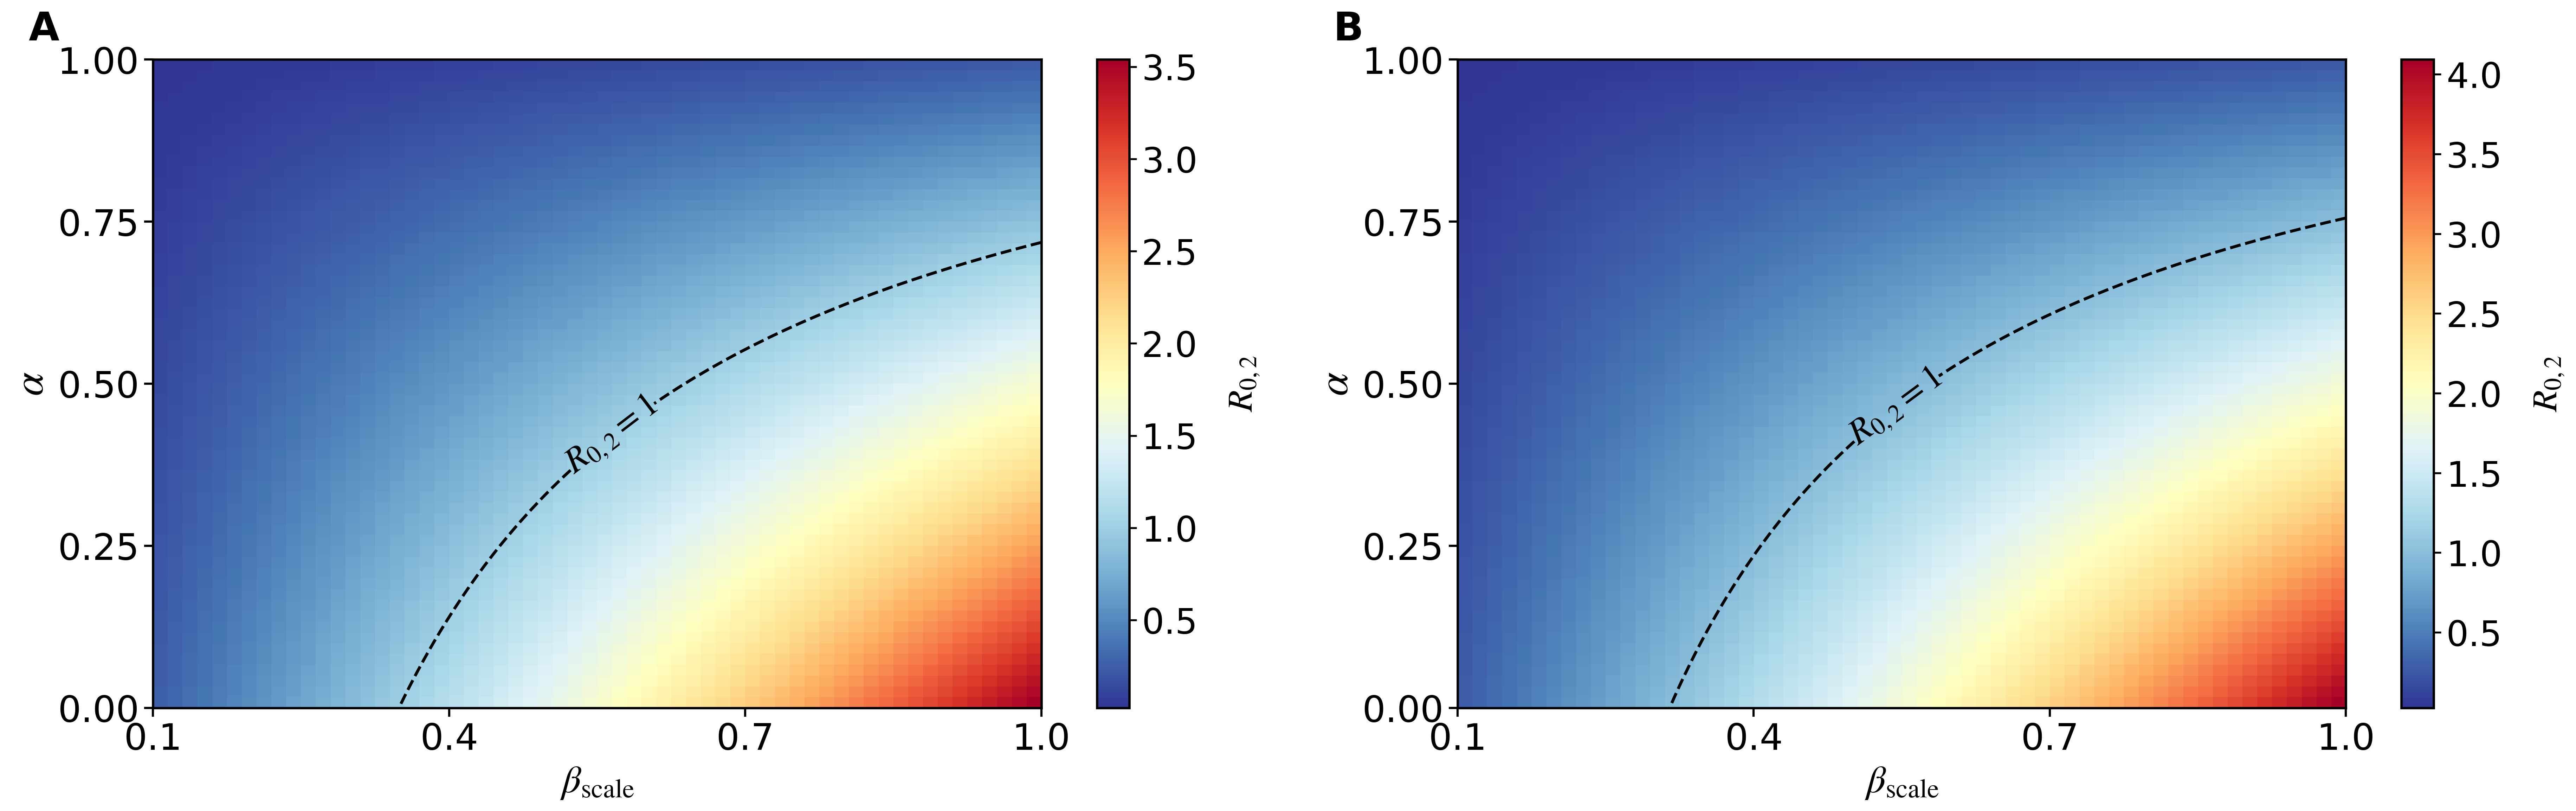

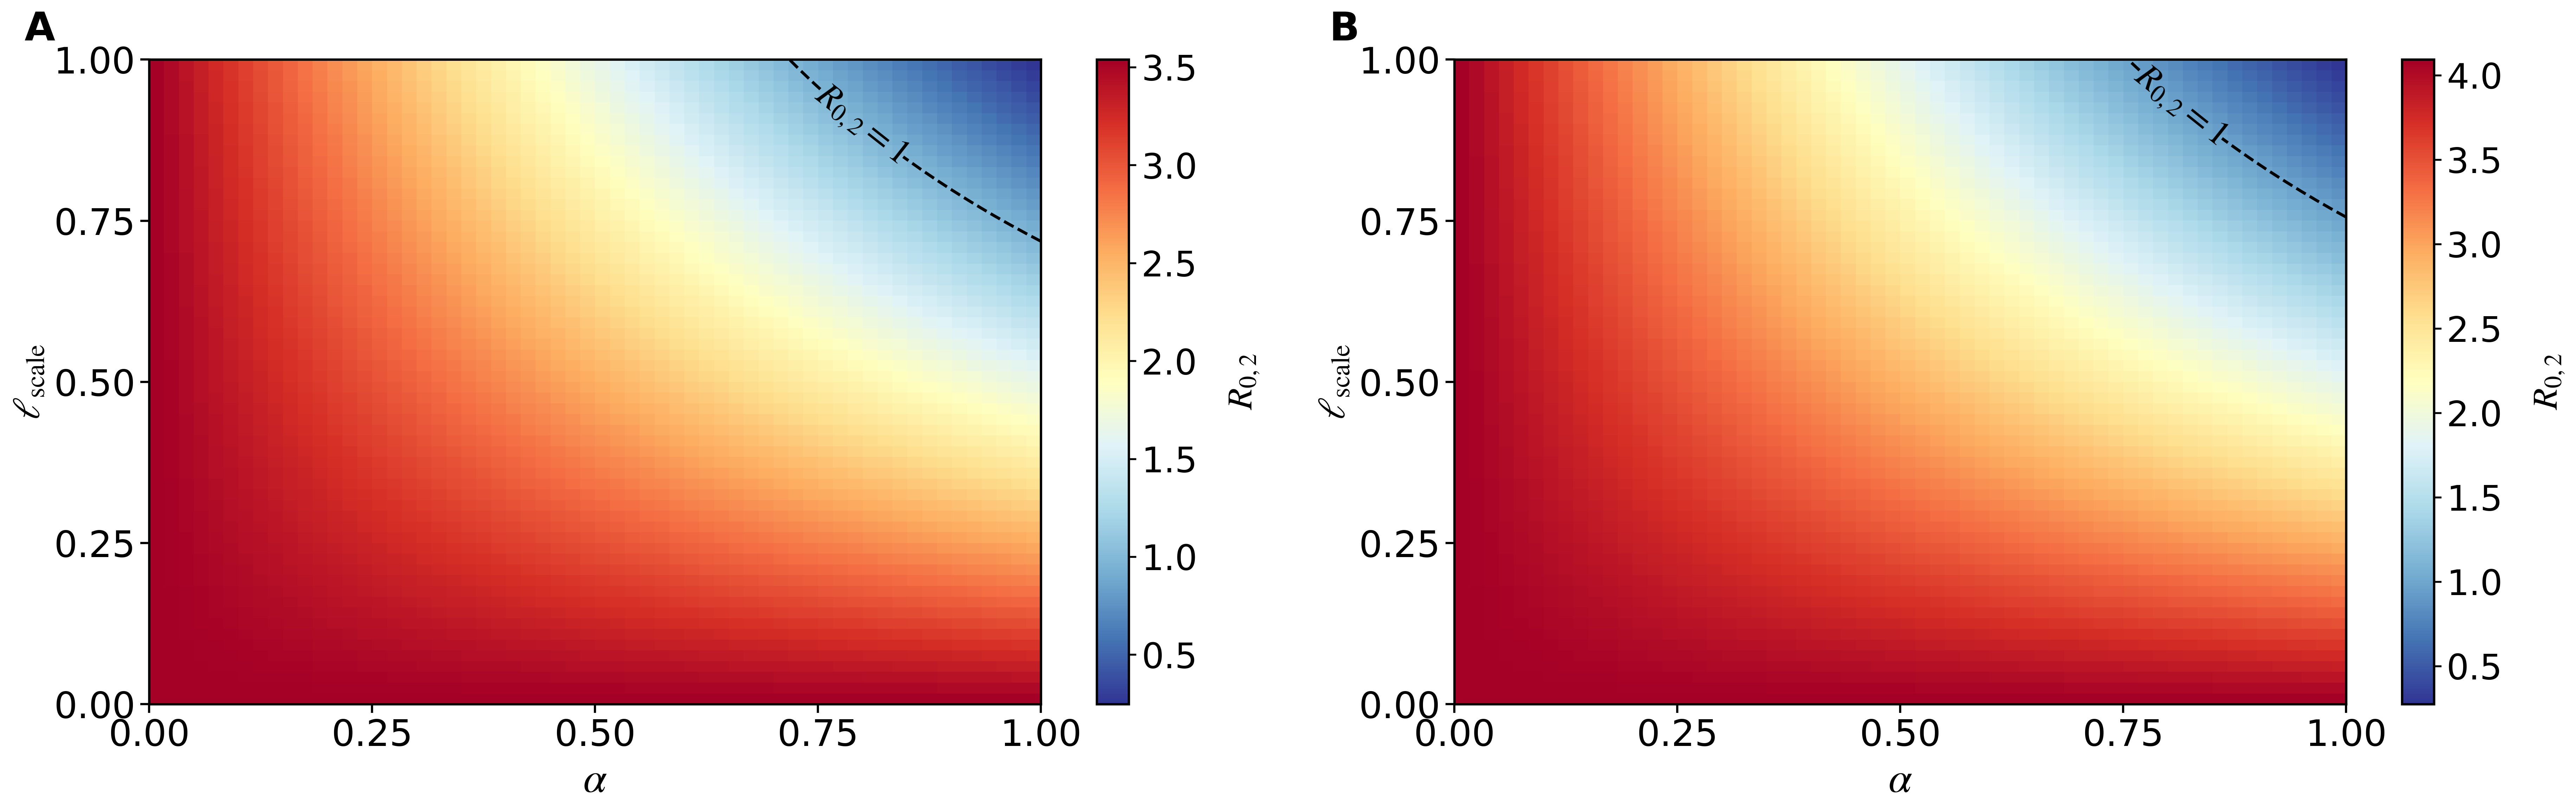

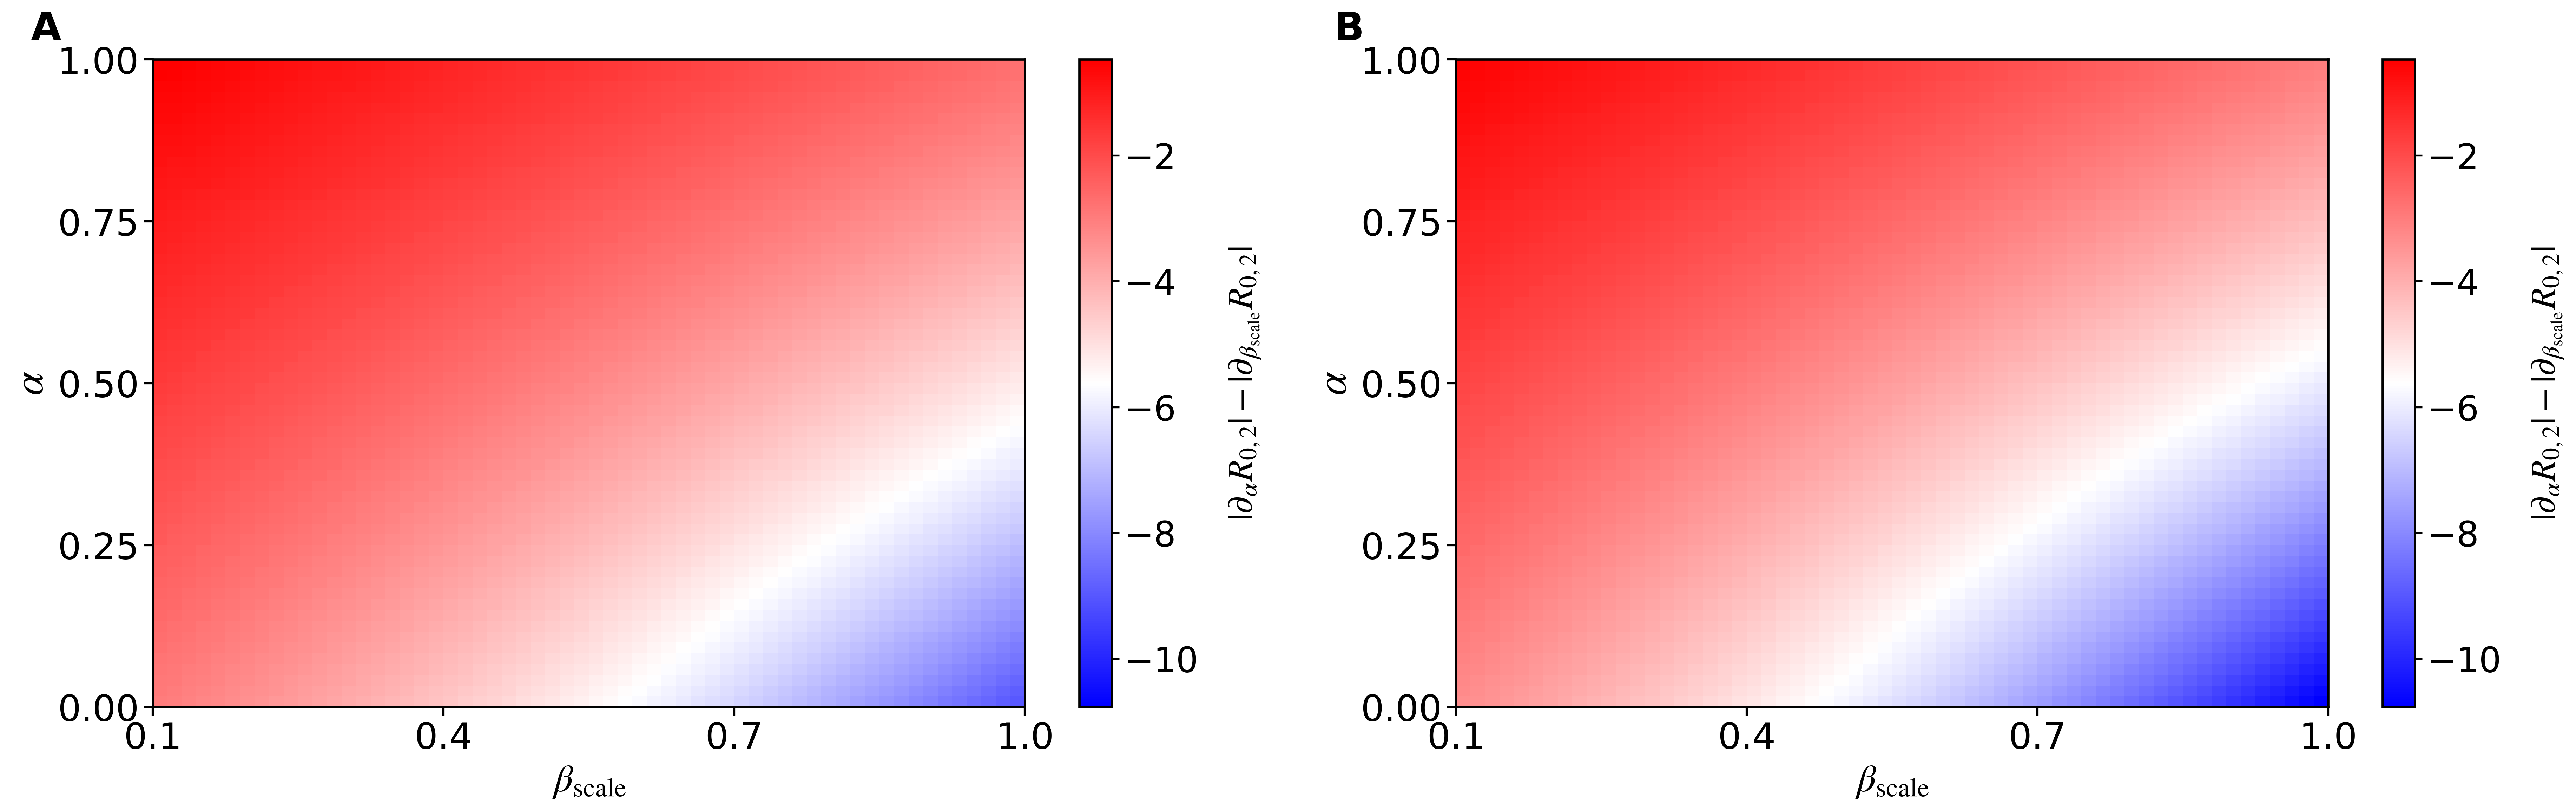

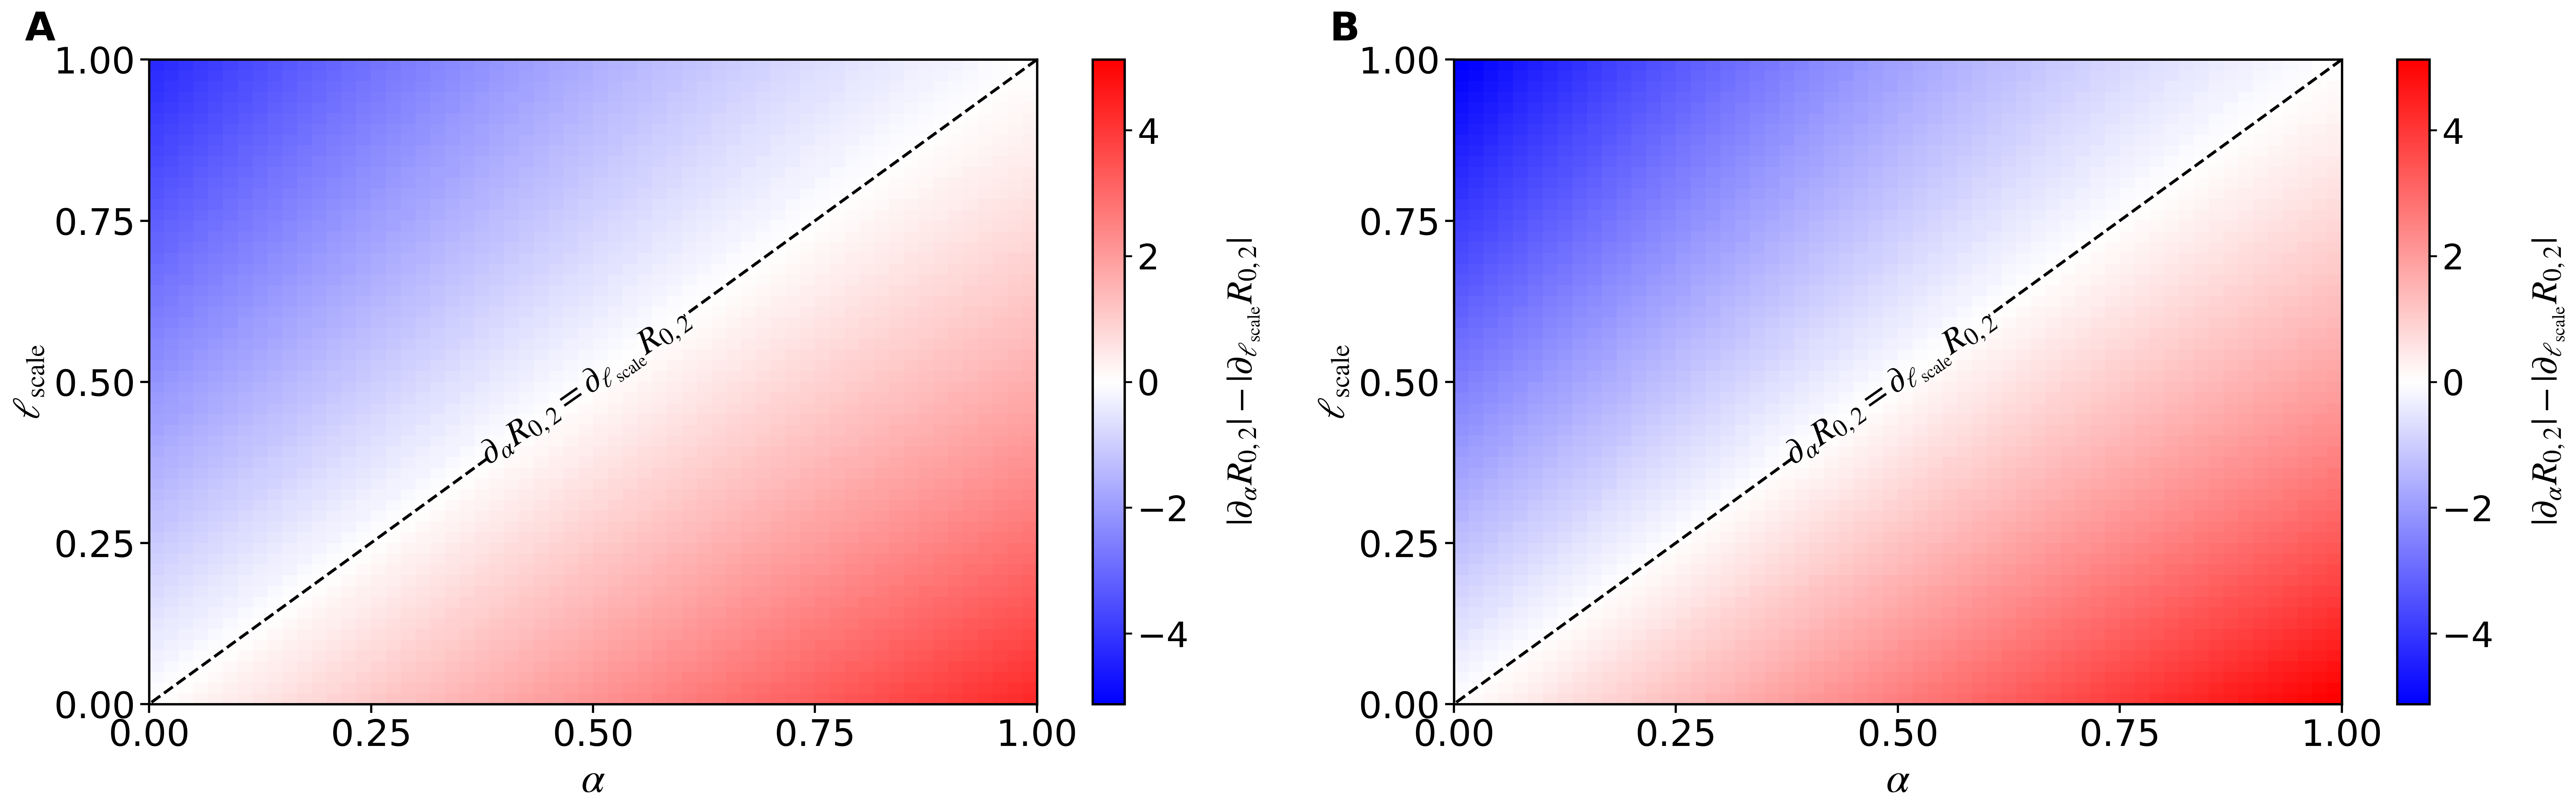

In [5]:
# ============================================================
# FUNCTION: PRINT CONTOUR START AND END COORDINATES
# ============================================================
import numpy as np
import matplotlib.pyplot as plt



def print_contour_endpoints(
    cs,
    x_name,
    y_name,
    contour_name,
    panel_label
):

    print("\n" + "="*75)
    print(f"{contour_name} : Panel {panel_label}")
    print("="*75)

    paths = cs.get_paths()

    if len(paths) == 0:
        print("No contour found.")
        return

    for n, path in enumerate(paths, start=1):

        vertices = path.vertices

        if len(vertices) < 2:
            continue

        x_start, y_start = vertices[0]
        x_end, y_end = vertices[-1]

        print(f"Segment {n}:")
        print(
            f"    START : "
            f"{x_name} = {x_start:.6f}, "
            f"{y_name} = {y_start:.6f}"
        )
        print(
            f"    END   : "
            f"{x_name} = {x_end:.6f}, "
            f"{y_name} = {y_end:.6f}"
        )


# ============================================================
# FIGURE 1 : R0 beta vs eta
# ============================================================

fig, axes = plt.subplots(1, 2, figsize=(25, 8))

datasets = [
    (rural_beta_R0, 'A'),
    (urban_beta_R0, 'B')
]

for ax, (Rmap, label) in zip(axes, datasets):

    im = ax.imshow(
        Rmap,
        origin='lower',
        aspect='auto',
        extent=[
            beta_vals.min(),
            beta_vals.max(),
            eta_vals.min(),
            eta_vals.max()
        ],
        cmap='RdYlBu_r'
    )

    # --------------------------------------------------------
    # R0 = 1 CONTOUR
    # --------------------------------------------------------

    cs = ax.contour(
        beta_vals,
        eta_vals,
        Rmap,
        levels=[1],
        colors='black',
        linewidths=2,
        linestyles='--'
    )

    ax.clabel(
        cs,
        fmt={1: r'$R_{0,2}=1$'},
        fontsize=24,
        manual=[(0.55, 0.45)]
    )

    # --------------------------------------------------------
    # PRINT START / END COORDINATES
    # x = beta scale
    # y = alpha
    # --------------------------------------------------------

    print_contour_endpoints(
        cs,
        x_name='beta-scale',
        y_name='alpha',
        contour_name='R0 = 1 contour (Figure 1)',
        panel_label=label
    )

    # --------------------------------------------------------
    # AXIS LABELS
    # --------------------------------------------------------

    ax.set_xlabel(r'$\beta_{\mathrm{scale}}$', fontsize=26)
    ax.set_ylabel(r'$\alpha$', fontsize=29)

    ax.set_xticks(beta_ticks)
    ax.set_yticks(eta_ticks)

    # --------------------------------------------------------
    # TICKS
    # --------------------------------------------------------

    ax.tick_params(
        axis='both',
        which='major',
        labelsize=25,
        width=1.5,
        length=6
    )

    # --------------------------------------------------------
    # PANEL LABEL
    # --------------------------------------------------------

    ax.text(
        -0.14,
        1.03,
        label,
        transform=ax.transAxes,
        fontsize=27,
        fontweight='bold'
    )

    # --------------------------------------------------------
    # COLORBAR
    # --------------------------------------------------------

    cbar = fig.colorbar(im, ax=ax)
    cbar.set_label(r'$R_{0,2}$', rotation=90, labelpad=20, fontsize=24)
    cbar.ax.tick_params(labelsize=24, width=1.3, length=5)


plt.tight_layout()

fig.savefig(
    FIG_CONTOUR / "Mozmb_R0_beta_eta.png",
    dpi=300,
    bbox_inches='tight'
)


# ============================================================
# FIGURE 2 : R0 ell vs eta
# ============================================================

fig, axes = plt.subplots(1, 2, figsize=(25, 8))

datasets = [
    (rural_ell_R0, 'A'),
    (urban_ell_R0, 'B')
]

for ax, (Rmap, label) in zip(axes, datasets):

    im = ax.imshow(
        Rmap,
        origin='lower',
        aspect='auto',
        extent=[
            eta_vals.min(),
            eta_vals.max(),
            ell_vals.min(),
            ell_vals.max()
        ],
        cmap='RdYlBu_r'
    )

    # --------------------------------------------------------
    # R0 = 1 CONTOUR
    # --------------------------------------------------------

    cs = ax.contour(
        eta_vals,
        ell_vals,
        Rmap,
        levels=[1],
        colors='black',
        linewidths=2,
        linestyles='--'
    )

    ax.clabel(
        cs,
        fmt={1: r'$R_{0,2}=1$'},
        fontsize=24,
        manual=[(0.55, 0.45)]
    )

    # --------------------------------------------------------
    # PRINT START / END COORDINATES
    # x = alpha
    # y = ell-scale
    # --------------------------------------------------------

    print_contour_endpoints(
        cs,
        x_name='alpha',
        y_name='ell-scale',
        contour_name='R0 = 1 contour (Figure 2)',
        panel_label=label
    )

    # --------------------------------------------------------
    # AXIS LABELS
    # --------------------------------------------------------

    ax.set_xlabel(r'$\alpha$', fontsize=29)
    ax.set_ylabel(r'$\ell_{\mathrm{scale}}$', fontsize=26)

    ax.set_xticks(eta_ticks)
    ax.set_yticks(ell_ticks)

    # --------------------------------------------------------
    # TICKS
    # --------------------------------------------------------

    ax.tick_params(
        axis='both',
        which='major',
        labelsize=25,
        width=1.5,
        length=6
    )

    # --------------------------------------------------------
    # PANEL LABEL
    # --------------------------------------------------------

    ax.text(
        -0.14,
        1.03,
        label,
        transform=ax.transAxes,
        fontsize=27,
        fontweight='bold'
    )

    # --------------------------------------------------------
    # COLORBAR
    # --------------------------------------------------------

    cbar = fig.colorbar(im, ax=ax)
    cbar.set_label(r'$R_{0,2}$', rotation=90, labelpad=20, fontsize=24)
    cbar.ax.tick_params(labelsize=24, width=1.3, length=5)


plt.tight_layout()

fig.savefig(
    FIG_CONTOUR / "Mozmb_R0_ell_eta.png",
    dpi=300,
    bbox_inches='tight'
)


# ============================================================
# FIGURE 3 : Dominance beta vs eta
# ============================================================

fig, axes = plt.subplots(1, 2, figsize=(25, 8))

datasets = [
    (rural_beta_D, 'A'),
    (urban_beta_D, 'B')
]

for ax, (Dmap, label) in zip(axes, datasets):

    im = ax.imshow(
        Dmap,
        origin='lower',
        aspect='auto',
        extent=[
            beta_vals.min(),
            beta_vals.max(),
            eta_vals.min(),
            eta_vals.max()
        ],
        cmap='bwr',
        vmin=dom_beta_vmin,
        vmax=dom_beta_vmax
    )

    # --------------------------------------------------------
    # DOMINANCE BOUNDARY
    #
    # |dR0/dalpha| - |dR0/dbeta| = 0
    # --------------------------------------------------------

    cs = ax.contour(
        beta_vals,
        eta_vals,
        Dmap,
        levels=[0],
        colors='black',
        linewidths=2,
        linestyles='--'
    )

    # --------------------------------------------------------
    # SAFE LABELING
    # --------------------------------------------------------

    placed = False

    for seg_group in cs.allsegs:

        if len(seg_group) > 0:

            seg = seg_group[0]

            if len(seg) > 0:

                mid_point = tuple(
                    seg[len(seg) // 2]
                )

                ax.clabel(
                    cs,
                    fmt={
                        0:
                        r'$\partial_\alpha R_0'
                        r' = \partial_{\beta_{\mathrm{scale}}} R_0$'
                    },
                    fontsize=24,
                    manual=[mid_point]
                )

                placed = True
                break

    # --------------------------------------------------------
    # FALLBACK
    # --------------------------------------------------------

    if not placed:

        ax.clabel(
            cs,
            fmt={
                0:
                r'$\partial_\alpha R_{0,2}'
                r' = \partial_{\beta_{\mathrm{scale}}} R_{0,2}$'
            },
            fontsize=24
        )

    # --------------------------------------------------------
    # PRINT START / END COORDINATES
    #
    # x = beta scale
    # y = alpha
    # --------------------------------------------------------

    print_contour_endpoints(
        cs,
        x_name='beta-scale',
        y_name='alpha',
        contour_name='Dominance boundary (Figure 3)',
        panel_label=label
    )

    # --------------------------------------------------------
    # AXIS LABELS
    # --------------------------------------------------------

    ax.set_xlabel(r'$\beta_{\mathrm{scale}}$', fontsize=26)
    ax.set_ylabel(r'$\alpha$', fontsize=29)

    ax.set_xticks(beta_ticks)
    ax.set_yticks(eta_ticks)

    # --------------------------------------------------------
    # TICKS
    # --------------------------------------------------------

    ax.tick_params(
        axis='both',
        which='major',
        direction='out',
        length=6,
        width=1.5,
        labelsize=25,
        bottom=True,
        top=False,
        left=True,
        right=False
    )

    # --------------------------------------------------------
    # PANEL LABEL
    # --------------------------------------------------------

    ax.text(
        -0.14,
        1.03,
        label,
        transform=ax.transAxes,
        fontsize=27,
        fontweight='bold'
    )

    # --------------------------------------------------------
    # COLORBAR
    # --------------------------------------------------------

    cbar = fig.colorbar(im, ax=ax)

    cbar.set_label(
        r'$|\partial_\alpha R_{0,2}|'
        r' - |\partial_{\beta_{\mathrm{scale}}} R_{0,2}|$',
        rotation=90, labelpad=20, fontsize=24
    )

    cbar.ax.tick_params(
        labelsize=24,
        width=1.3,
        length=5
    )


plt.tight_layout()

fig.savefig(
    FIG_CONTOUR / "Mozmb_Dominance_beta_eta.png",
    dpi=300,
    bbox_inches='tight'
)


# ============================================================
# FIGURE 4 : Dominance ell vs eta
# ============================================================

fig, axes = plt.subplots(1, 2, figsize=(25, 8))

datasets = [
    (rural_ell_D, 'A'),
    (urban_ell_D, 'B')
]

for ax, (Dmap, label) in zip(axes, datasets):

    im = ax.imshow(
        Dmap,
        origin='lower',
        aspect='auto',
        extent=[
            eta_vals.min(),
            eta_vals.max(),
            ell_vals.min(),
            ell_vals.max()
        ],
        cmap='bwr',
        vmin=dom_ell_vmin,
        vmax=dom_ell_vmax
    )

    # --------------------------------------------------------
    # DOMINANCE BOUNDARY
    #
    # |dR0/dalpha| - |dR0/dell| = 0
    # --------------------------------------------------------

    cs = ax.contour(
        eta_vals,
        ell_vals,
        Dmap,
        levels=[0],
        colors='black',
        linewidths=2,
        linestyles='--'
    )

    # --------------------------------------------------------
    # SAFE LABELING
    # --------------------------------------------------------

    placed = False

    for seg_group in cs.allsegs:

        if len(seg_group) > 0:

            seg = seg_group[0]

            if len(seg) > 0:

                mid_point = tuple(
                    seg[len(seg) // 2]
                )

                ax.clabel(
                    cs,
                    fmt={
                        0:
                        r'$\partial_\alpha R_{0,2}'
                        r' = \partial_{\ell_{\mathrm{scale}}} R_{0,2}$'
                    },
                    fontsize=24,
                    manual=[mid_point]
                )

                placed = True
                break

    # --------------------------------------------------------
    # FALLBACK
    # --------------------------------------------------------

    if not placed:

        ax.clabel(
            cs,
            fmt={
                0:
                r'$\partial_\alpha R_{0,2}'
                r' = \partial_{\ell_{\mathrm{scale}}} R_{0,2}$'
            },
            fontsize=24
        )

    # --------------------------------------------------------
    # PRINT START / END COORDINATES
    #
    # x = alpha
    # y = ell scale
    # --------------------------------------------------------

    print_contour_endpoints(
        cs,
        x_name='alpha',
        y_name='ell-scale',
        contour_name='Dominance boundary (Figure 4)',
        panel_label=label
    )

    # --------------------------------------------------------
    # AXIS LABELS
    # --------------------------------------------------------

    ax.set_xlabel(r'$\alpha$', fontsize=29)
    ax.set_ylabel(r'$\ell_{\mathrm{scale}}$', fontsize=26)

    ax.set_xticks(eta_ticks)
    ax.set_yticks(ell_ticks)

    # --------------------------------------------------------
    # TICKS
    # --------------------------------------------------------

    ax.tick_params(
        axis='both',
        which='major',
        direction='out',
        length=6,
        width=1.5,
        labelsize=25,
        bottom=True,
        top=False,
        left=True,
        right=False
    )

    # --------------------------------------------------------
    # PANEL LABEL
    # --------------------------------------------------------

    ax.text(
        -0.14,
        1.03,
        label,
        transform=ax.transAxes,
        fontsize=27,
        fontweight='bold'
    )

    # --------------------------------------------------------
    # COLORBAR
    # --------------------------------------------------------

    cbar = fig.colorbar(im, ax=ax)

    cbar.set_label(
        r'$|\partial_\alpha R_{0,2}|'
        r' - |\partial_{\ell_{\mathrm{scale}}} R_{0,2}|$',
        rotation=90, labelpad=25, fontsize=25
    )

    cbar.ax.tick_params(
        labelsize=24,
        width=1.3,
        length=5
    )


plt.tight_layout()

fig.savefig(
    FIG_CONTOUR / "Mozmb_Dominance_ell_eta.png",
    dpi=300,
    bbox_inches='tight'
)


# ============================================================
# SHOW ALL FIGURES
# ============================================================

plt.show()